---
title : "Analyse statistique et visualisation : le jeu de données du Titanic"
---

Le naufrage du Titanic est l'un des plus célèbres de l'histoire. Le 15 avril 1912, lors de son voyage inaugural, le RMS Titanic, un paquebot transatlantique britannique, a sombré après être entré en collision avec un iceberg, tuant 1502 passagers et membres d'équipage sur 2224. L'une des raisons pour lesquelles le naufrage a causé tant de morts est qu'il n'y avait pas assez de canots de sauvetage pour les passagers et l'équipage. On a toujours entendu dire que certains groupes de personnes étaient plus susceptibles de survivre que d'autres, comme les femmes, les enfants et les classes supérieures. Nous allons analyser les données pour vérifier ces affirmations.

Dans cet exemple, nous allons récupérer un jeu de données (liste de personnes, caractéristiques, survivants ou non…) et analyser quelles catégories de personnes ont survécu. Nous utiliserons les bibliothèques **pandas**, **Matplotlib**, **Seaborn** et **Plotly** pour explorer et visualiser ces données.

![Titanic](https://upload.wikimedia.org/wikipedia/commons/thumb/f/fd/RMS_Titanic_3.jpg/1024px-RMS_Titanic_3.jpg)

## Importation des données

In [394]:
# Import data analysis libraries
# ==============================
import pandas as pd 
import numpy as np


# Import visualization libraries and set favourite style
# ======================================================
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 12
plt.rcParams['figure.figsize'] = (12, 6) # set default size of plots
# plt.style.use('ggplot') # set ggplot style

import seaborn as sns
sns.set_theme(style = "ticks", # "ticks", "whitegrid", "darkgrid", "white", "dark"
              palette = "pastel", # None, Set2, husl, deep, muted, bright, pastel, dark, colorblind
              rc = {"axes.spines.right": False, "axes.spines.top": False})


import plotly.express as px
from plotly.subplots import make_subplots

# Import Notebook display library
# ==============================
from IPython.display import display, Markdown

L'une des forces de pandas est l'importation et l'exportation des données. Ce package possède un ensemble de fonctions très large pour charger des données en mémoire et les exporter dans divers formats.

Pandas dédie un sous-répertoire entier du package à l'importation et à l'exportation vers des formats de données exploitables avec d'autres outils. On peut citer les formats csv, txt, Excel®, SAS®, SQL, HDF5 entre autres. Suivant le format, les outils seront différents, mais les principes restent les mêmes. Ainsi, nous allons considérer uniquement le format `csv`.

Un fichier **CSV** (.csv) est un fichier de données tabulaires. Le sigle CSV signifie *Comma Separated Values* qui se traduit par « valeurs séparées par des virgules ». L'avantage de ce type de fichier est qu'il s'agit d'un fichier texte qui ne conserve que les données du tableau (pas de mise en page) et peut être lu par n'importe quel tableur. Les données d'une même ligne sont souvent séparées par des points-virgules ou des virgules.

Pour importer les données stockées dans un fichier csv dont les éléments sont séparés par des virgules, on utilisera :
```python
df = pd.read_csv('nom_du_fichier.csv', sep=',')
```

Dans l'exemple suivant nous allons importer et afficher un fichier csv contenant des données sur le Titanic.

In [395]:
df = pd.read_csv('titanic.csv')

## Étude globale de l'ensemble de données

<div class="alert alert-info">

Dans cette partie nous allons utiliser les méthodes suivantes :
```python
.shape
.info()
.head() .tail()
.columns
.isnull() .dropna() .fillna()
.unique() .nunique() .value_counts()
.describe() .min(), .max(), .mean(), .median(), .std()
```

</div>

La première étape de tout projet d'analyse de données consiste à examiner les données. Nous devons voir combien d'observations (lignes) et combien d'entités (colonnes) sont contenues, ce que signifient ces colonnes, et ainsi de suite. Cela nous aidera à nous familiariser avec l'ensemble de données, et pourrait même nous aider à évaluer quelles informations sont importantes et lesquelles ne le sont pas.

In [396]:
df.shape # tailles du dataset : 1309 lignes et 7 colonnes
# df.columns

(1309, 7)

Un moyen rapide de vérifier le contenu consiste à appeler les 5 premières lignes à l'aide de la méthode `.head()` sans spécifier l'argument entre parenthèses. Si nous voulons vérifier les 20 premières lignes, nous mettons 20 comme argument.

In [397]:
# df
df.head(20)
# df.tail(10)

,classe,survivant,nom,sexe,age,prix,port_depart
0,1,1,"Allen, Miss. Elisabeth Walton",F,29.0000,211.3375,S
1,1,1,"Allison, Master. Hudson Trevor",H,0.9167,151.5500,S
2,1,0,"Allison, Miss. Helen Loraine",F,2.0000,151.5500,S
3,1,0,"Allison, Mr. Hudson Joshua Creighton",H,30.0000,151.5500,S
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",F,25.0000,151.5500,S
5,1,1,"Anderson, Mr. Harry",H,48.0000,26.5500,S
6,1,1,"Andrews, Miss. Kornelia Theodosia",F,63.0000,77.9583,S
7,1,0,"Andrews, Mr. Thomas Jr",H,39.0000,0.0000,S
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",F,53.0000,51.4792,S
9,1,0,"Artagaveytia, Mr. Ramon",H,71.0000,49.5042,C


On compte 7 caractéristiques (colonnes) décrivant chaque personne à bord du Titanic. Notre caractéristique cible (également appelée variable dépendante) est la colonne `survivant`, qui vaut 1 si la personne a survécu et 0 sinon. Dans ce cas, il est facile de déduire que cette colonne ne contient que des valeurs numériques 0 et 1. Cependant, pour d'autres caractéristiques (ou variables indépendantes), il peut ne pas être possible de déduire au premier coup d'œil le type de données contenues.

Afin de générer rapidement un tableau des types de données contenus dans chaque colonne, nous utilisons la méthode `.info()`.  

In [398]:
# Info about data frame dimensions, column types, and file size

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   classe       1309 non-null   int64  
 1   survivant    1309 non-null   int64  
 2   nom          1309 non-null   object 
 3   sexe         1309 non-null   object 
 4   age          1046 non-null   float64
 5   prix         1308 non-null   float64
 6   port_depart  1307 non-null   object 
dtypes: float64(2), int64(2), object(3)
memory usage: 71.7+ KB


### Données manquantes ?

Combien de valeurs manquantes dans chaque colonne ?

In [399]:
df.isnull().sum()

classe           0
survivant        0
nom              0
sexe             0
age            263
prix             1
port_depart      2
dtype: int64

Il est utile d'utiliser la méthode `.isnull()` combinée avec `.sum()` ou `.mean()` pour connaître l'ampleur des valeurs manquantes dans un jeu de données.

In [400]:
df.isnull().mean().sort_values(ascending = False)


age            0.200917
port_depart    0.001528
prix           0.000764
classe         0.000000
survivant      0.000000
nom            0.000000
sexe           0.000000
dtype: float64

Nous pouvons voir que la colonne `port_depart` contient 2 valeurs manquantes (indiquées par `NaN`). Qui sont les passagers pour lesquels on n'a pas ces informations ?

In [401]:
# mask = df['age'].isnull()
# df.loc[mask] # il y a 263 valeurs manquantes pour l'age, car 1309-1046=263

mask = df['port_depart'].isnull()
df.loc[mask]

,classe,survivant,nom,sexe,age,prix,port_depart
168,1,1,"Icard, Miss. Amelie",F,38.0,80.0,NaN
284,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",F,62.0,80.0,NaN


De même, nous pouvons voir que dans la colonne `age` il manque 263 données (nous n'allons pas les afficher). Peut-être que ces données n'ont pas été collectées ou ont été perdues. Que faire ? Nous pourrions soit supprimer ces lignes, soit remplacer les valeurs manquantes par la moyenne de l'âge des passagers par exemple. Les choix relatifs au traitement des valeurs manquantes ne sont pas des choix méthodologiques neutres. Pandas donne les outils techniques pour faire ceci mais la question de la légitimité de ces choix et de leur pertinence est propre à chaque jeu de données.

Pour le moment nous n'allons pas modifier les données.

In [402]:
# Option 1 : éliminer les lignes avec des valeurs manquantes
# df = df.dropna(axis=0)
# df.shape  # (1046, 7)

# Option 2 : remplacer par la moyenne (Attention : on modifie la réalité)
# df.fillna(df['age'].mean(), inplace=True)

### Valeurs uniques dans chaque colonne et doublons

Pour chaque colonne, nous voulons connaître **combien de valeurs différentes** elle contient, **lesquelles** sont ces valeurs et **combien de fois chacune apparaît**.



Pour le nombre de valeurs différentes par colonne, nous avons :

In [403]:
df.nunique()

classe            3
survivant         2
nom            1307
sexe              2
age              98
prix            281
port_depart       3
dtype: int64

On note que la colonne `classe` ne contient que 3 valeurs différentes, la colonne `survivant` ne contient que 2 valeurs différentes, la colonne `sexe` ne contient que 2 valeurs différentes, la colonne `port_depart` ne contient que 3 valeurs différentes. Pour ces colonnes ayant moins de 5 valeurs différentes, nous pouvons lister quelles sont ces valeurs différentes en utilisant la méthode `.unique()` :

In [404]:
filtre = [df[col].nunique() < 5 for col in df.columns]

for col in df[df.columns[filtre]]:
    print(col, df[col].unique())

classe [1 2 3]
survivant [1 0]
sexe ['F' 'H']
port_depart ['S' 'C' nan 'Q']


Pour une colonne donnée, nous pouvons lister non seulement les valeurs différentes en utilisant la méthode `.unique()`, mais aussi compter le nombre d'occurrences de chaque valeurs différentes en utilisant la méthode `.value_counts()`. Par exemple, elle peut nous dire combien de passagers étaient dans chaque classe :

In [405]:
df['classe'].value_counts()

classe
3    709
1    323
2    277
Name: count, dtype: int64

In [406]:
# Résumé pour une colonne donnée
# ==============================

colonne = df['classe']

display(Markdown("**Résumé statistique de la colonne 'classe'**"))
display(colonne.describe())

display(Markdown("**Nombre de valeurs uniques**"))
display(colonne.nunique())

display(Markdown("**Valeurs uniques**"))
display(colonne.unique())

display(Markdown("**Combien d'occurrences de chaque valeur unique**"))
display(colonne.value_counts())

display(Markdown("**Proportions des valeurs uniques**"))
display(colonne.value_counts(normalize=True))  # proportions

**Résumé statistique de la colonne 'classe'**

count    1309.000000
mean        2.294882
std         0.837836
min         1.000000
25%         2.000000
50%         3.000000
75%         3.000000
max         3.000000
Name: classe, dtype: float64

**Nombre de valeurs uniques**

3

**Valeurs uniques**

array([1, 2, 3])

**Combien d'occurrences de chaque valeur unique**

classe
3    709
1    323
2    277
Name: count, dtype: int64

**Proportions des valeurs uniques**

classe
3    0.541635
1    0.246753
2    0.211612
Name: proportion, dtype: float64

Pour avoir une idée visuelle du nombre de passagers par classe, on peut afficher ces informations 

- soit avec la fonction `.plot()` de pandas en spécifiant le type de graphique `bar` ou `pie`, 
- soit avec la fonction `countplot()` de Seaborn  
- soit avec les fonctions `histogram()` ou `pie()` de Plotly.

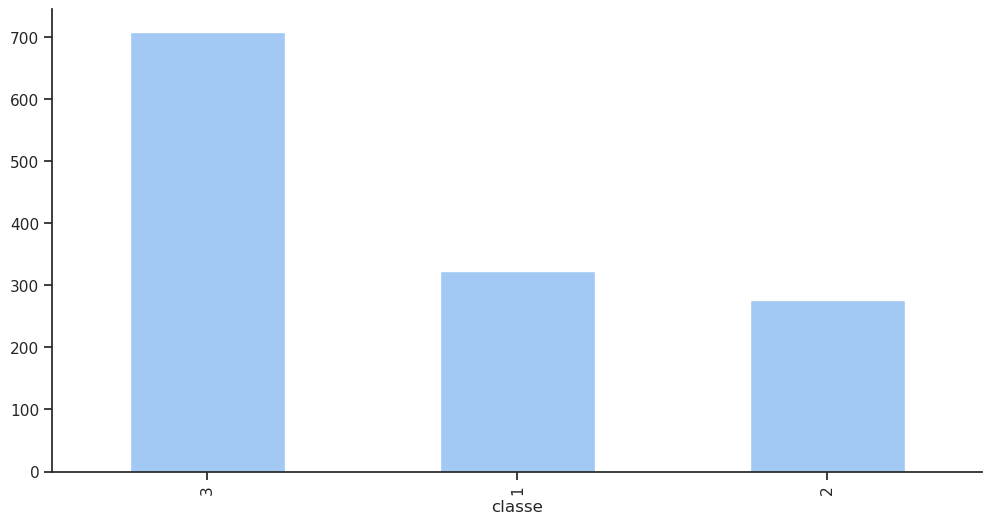

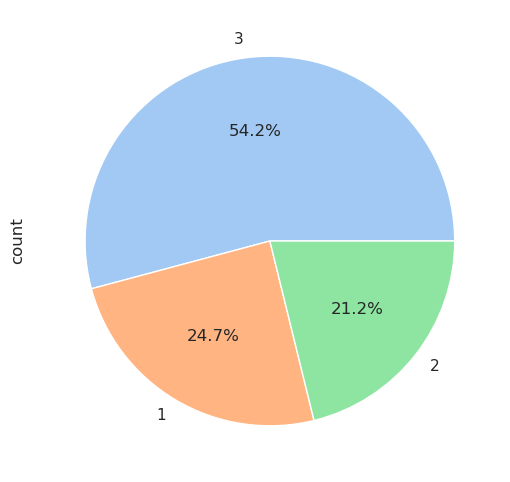

In [407]:
# Avec .plot() de Pandas
# ------------------------------
colonne.value_counts().plot(kind='bar');  # histogramme
plt.figure()
colonne.value_counts().plot(kind='pie', autopct='%1.1f%%');  # camembert

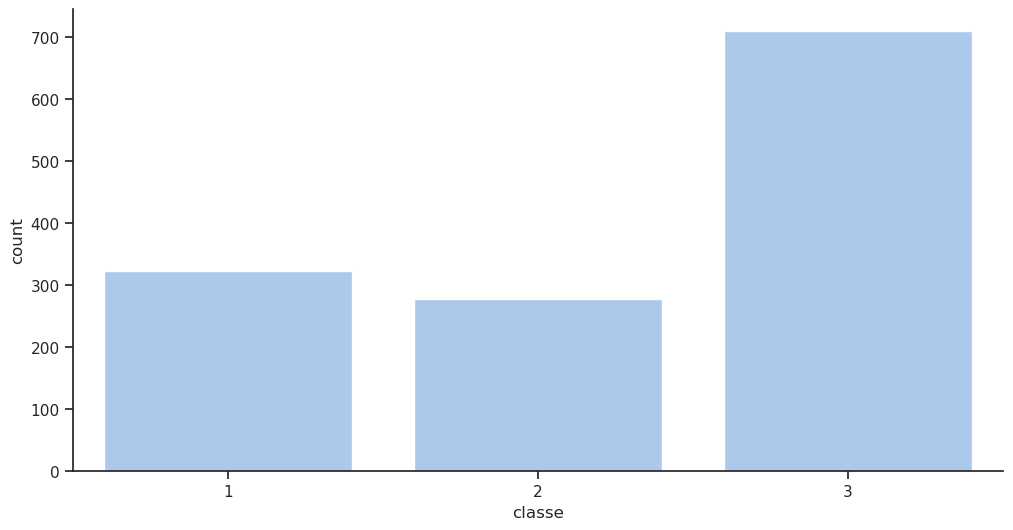

In [408]:
# Avec seaborn
# ------------------------------
sns.countplot(data=df, x=colonne);  # histogramme

# Note: Seaborn n'a pas de fonction native pour les diagrammes circulaires (pie charts)
# Il est recommandé d'utiliser matplotlib ou plotly pour ce type de visualisation

In [409]:
# Avec plotly.express
# ------------------------------
px.histogram(df, x=colonne, 
             text_auto=True,
             )

In [410]:
px.pie(df, names=colonne)

### Bilan sur l'ensemble de données

**Conclusion** : nous savons maintenant que ce jeu de données comporte 1309 lignes et 7 colonnes. 4 colonnes sont de type numérique (flottants et entiers), 3 colonnes sont non numériques :

- `classe` : valeurs possibles 1, 2 ou 3
- `survivant` : 0 (décédé), 1 (a survécu)
- `nom` : nom, prénom et titre
- `sexe` : H (homme), F (femme)
- `age` : en années
- `prix` : prix du ticket
- `port_depart` : port d'embarquement (C = Cherbourg, S = Southampton, Q = Queenstown)

### Statistiques descriptives

Pour les colonnes numériques telles que `age`, `prix`, etc., nous aimerions connaître leurs valeurs moyennes, maximales et minimales pour voir si les données sont raisonnablement distribuées ou s'il y a des anomalies. Pour afficher un tableau de statistiques pour chaque colonne numérique, nous utilisons la méthode `.describe()`.

In [411]:
# df.describe(include='all')
display(df.describe())
display(df.describe(include='object'))

,classe,survivant,age,prix
count,1309.000000,1309.000000,1046.000000,1308.000000
mean,2.294882,0.381971,29.881135,33.295479
std,0.837836,0.486055,14.413500,51.758668
min,1.000000,0.000000,0.166700,0.000000
25%,2.000000,0.000000,21.000000,7.895800
50%,3.000000,0.000000,28.000000,14.454200
75%,3.000000,1.000000,39.000000,31.275000
max,3.000000,1.000000,80.000000,512.329200


,nom,sexe,port_depart
count,1309,1309,1307
unique,1307,2,3
top,"Connolly, Miss. Kate",H,S
freq,2,843,914


On note que la colonne `prix` a une valeur minimale de 0, ce qui semble étrange. Cela pourrait signifier que certaines personnes ont voyagé gratuitement.

### Plus jeune et plus vieux passagers

Une autre valeur qui attire l'attention est l'âge minimum, soit 0,1667 ans, avec un éventuel bébé de 2 mois à bord. De plus amples informations sur https://titanicfacts.net/titanic-passengers/ indiquent qu'il s'agit de Milvina Dean, une fille âgée de 2 mois et 13 jours au moment du naufrage. Vérifions si cette information est correcte :

In [412]:
mask = df['age'] == df['age'].min()
df.loc[mask]

,classe,survivant,nom,sexe,age,prix,port_depart
763,3,1,"Dean, Miss. Elizabeth Gladys ""Millvina""",F,0.1667,20.575,S


Et le plus jeune passager garçon ? Toujours selon le site précédent, il s'agit de Master Gilbert Sigvard Emanuel Danbom, âgé de 4 mois et 29 jours, qui n'a malheureusement pas survécu. Vérifions si cette information est correcte :

In [413]:
# Filtrer les individus dont sex == "H"
filtered_df = df.loc[df['sexe'] == "H"]
# Trouver l'âge minimum dans cette sous-table
min_age = filtered_df['age'].min()
# Sélectionner les lignes correspondant à cet âge minimum
youngest = filtered_df.loc[filtered_df['age'] == min_age]
# Afficher les résultats
youngest

,classe,survivant,nom,sexe,age,prix,port_depart
747,3,0,"Danbom, Master. Gilbert Sigvard Emanuel",H,0.3333,14.4,S


Et le passager le plus âgé ? Selon le site précédent, il s'agit de Mr Johan Svensson, âgé de 74 ans et 10 mois, qui n'a pas survécu. Cependant, notre jeu de données ne contient pas cette information :

In [414]:
df.loc[df['age']==df['age'].max()]

,classe,survivant,nom,sexe,age,prix,port_depart
14,1,1,"Barkworth, Mr. Algernon Henry Wilson",H,80.0,30.0,S


Et la femme la plus âgée ? Selon le site il s'agit de Mrs Mary Eliza Compton, âgée de 64 ans et 8 mois, qui a survécu. À nouveau, notre jeu de données ne contient pas cette information :

In [415]:
# Filtrer les individus dont sex == "F"
filtered_df = df.loc[df['sexe'] == "F"]
# Trouver l'âge maximum dans cette sous-table
max_age = filtered_df['age'].max()
# Sélectionner les lignes correspondant à cet âge maximum
oldest = filtered_df.loc[filtered_df['age'] == max_age]
# Afficher les résultats
oldest

,classe,survivant,nom,sexe,age,prix,port_depart
61,1,1,"Cavendish, Mrs. Tyrell William (Julia Florence...",F,76.0,78.85,S


### Curiosité

Sur Wikipedia, à la page [https://fr.m.wikipedia.org/wiki/Violet_Constance_Jessop](https://fr.m.wikipedia.org/wiki/Violet_Constance_Jessop)
il est indiqué que Violet Jessop, une hôtesse de la White Star Line, a survécu aux trois naufrages des navires de la classe Olympic, dont le Titanic. Vérifions si elle apparaît dans notre jeu de données :


In [416]:
df[df['nom'].str.contains('Violet', case=False, na=False)]

,classe,survivant,nom,sexe,age,prix,port_depart
501,2,1,"Mellinger, Miss. Madeleine Violet",F,13.0,19.5,S


La seule Violet dans notre jeu de données est une passagère de 13 ans, qui a embarqué à Southampton en 2ème classe. Elle a survécu au naufrage du Titanic mais n'est probablement pas la même personne que Violet Jessop.

## Analyse de chaque colonne individuellement

<div class="alert alert-info">

Dans cette partie nous allons utiliser les méthodes suivantes :

```python
.drop() .replace()
.value_counts()
.agg()
.cut() .map()
.plot(kind='bar') .plot(kind='hist')
sns.countplot() sns.catplot() sns.histplot()
```

</div>

Il n'est pas nécessaire de faire une analyse de chaque colonne individuellement, mais cela peut être utile pour comprendre les données.

### Colonne `nom`

On constate que la colonne `nom` contient 1307 valeurs uniques pour 1309 lignes, ce qui indique la présence de doublons. Affichons les lignes concernées pour examiner ces cas particuliers :

In [417]:
# keep=False signifie que chaque valeur de la colonne qui apparaît plus d'une fois sera marquée comme True
# Les valeurs uniques (apparaissant une seule fois) seront marquées comme False
duplicated_names = df['nom'].duplicated(keep=False)
df[duplicated_names]

,classe,survivant,nom,sexe,age,prix,port_depart
725,3,1,"Connolly, Miss. Kate",F,22.0,7.7500,Q
726,3,0,"Connolly, Miss. Kate",F,30.0,7.6292,Q
924,3,0,"Kelly, Mr. James",H,34.5,7.8292,Q
925,3,0,"Kelly, Mr. James",H,44.0,8.0500,S


Dans notre jeu de données, la colonne `nom` ne semble plus être pertinente pour l'analys qui va suivre. Nous pouvons la supprimer en utilisant la méthode `.drop()`. En effet, certaines colonnes peuvent être négligées si elles ne sont pas pertinentes pour l'analyse et inutile de les garder dans le DataFrame. 


In [418]:
# errors="ignore" pour éviter une erreur si la colonne n'existe pas
df.drop('nom', axis='columns', inplace=True, errors="ignore")

### Colonne `classe`

On a déjà vu que dans la colonne `classe` seulement trois catégories sont possibles : 1, 2 ou 3. De plus, on a vu que la méthode `.value_counts()` permet de compter le nombre d'occurrences pour chaque catégorie unique dans une colonne. 

Pour analyser plus en profondeur une colonne catégorielle, il est utile d'afficher à la fois :
- Le **nombre absolu** d'occurrences de chaque catégorie
- Le **pourcentage** que représente chaque catégorie par rapport au total
- Le traitement des **valeurs manquantes** (si présentes)

Comme ces informations sont intéressantes à afficher pour toute colonne catégorielle ou numérique discrète, nous allons créer une fonction réutilisable nommée `afficher_compte_et_pourcentage()` qui :
1. Calcule le nombre d'occurrences de chaque valeur unique
2. Calcule le pourcentage correspondant
3. Gère l'affichage des valeurs manquantes de manière explicite
4. Retourne un DataFrame synthétique facile à lire

Cette fonction sera ensuite appelée pour différentes colonnes en changeant simplement le nom de la colonne passée en paramètre.

In [419]:
def afficher_compte_et_pourcentage(df, colonne):
    compte = df[colonne].value_counts(dropna=False)
    pourcentage = df[colonne].value_counts(normalize=True, dropna=False) * 100
    resultat = pd.DataFrame({'Compte': compte, 'Pourcentage (%)': round(pourcentage, 2)})
    # Remplacer 'nan' dans l'index par 'Valeur manquante'
    resultat.index = resultat.index.map(lambda x: 'Valeur manquante' if pd.isna(x) else str(x))
    return resultat

In [420]:
afficher_compte_et_pourcentage(df, 'classe')

,Compte,Pourcentage (%)
classe,,
3,709,54.16
1,323,24.68
2,277,21.16


Ce tableau montre que la majorité des passagers (plus précisément 54 %) étaient de 3e classe. Fait intéressant, il y avait plus de passagers en première classe (323 passagers) qu'en seconde classe (277 passagers), même si la différence n'est pas très grande.

In [421]:
# Combien de fois chaque valeur unique apparaît dans la colonne ?
# ==================================================================

# Avec Pandas
# ------------------------------

# Avec la méthode value_counts() de la série, on peut obtenir le compte de chaque valeur unique dans la colonne.
# df['classe'].value_counts().sort_index().plot(kind='bar');


# Avec seaborn
# ------------------------------
# ax = sns.countplot(data=df, x='classe');
# Ajouter les annotations directement sur les barres
# for p in ax.patches:  # Les rectangles/barres sont dans ax.patches
#     ax.annotate(f'{int(p.get_height())}',  # Le texte est la hauteur de la barre
#                 (p.get_x() + p.get_width() / 2., p.get_height()),  # Position : centre de la barre
#                 ha='center', va='bottom', fontsize=10, color='black')  # Alignement et style

# Avec plotly.express
# ------------------------------
# px.histogram(df, x='classe', text_auto=True)
px.histogram(df, x='classe', text_auto=True).update_layout(bargap=0.2)

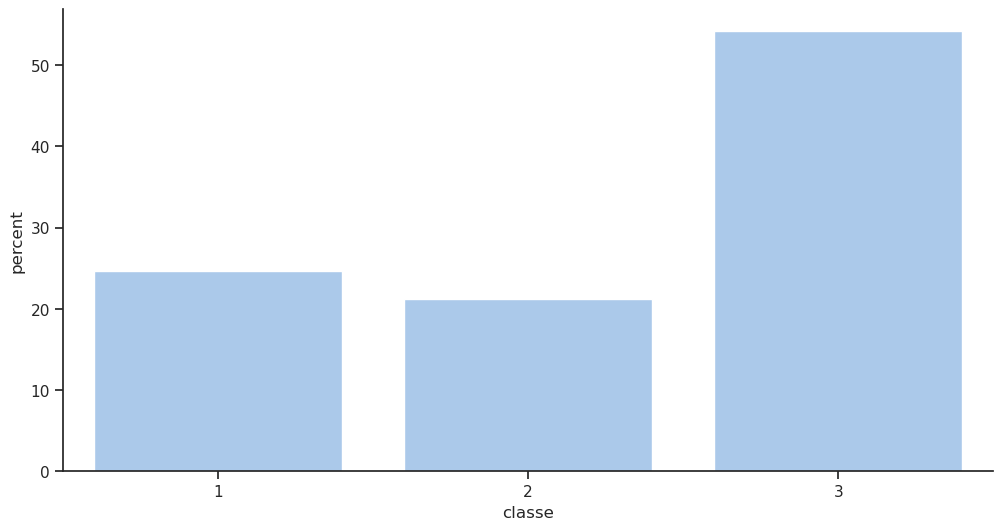

In [422]:
# Et en pourcentage ?
# ==================================================================

# Avec Seaborn
ax = sns.countplot(data=df, x='classe', stat='percent');

# Ajouter les annotations directement sur les barres
# for p in ax.patches:  # Les rectangles/barres sont dans ax.patches
#     ax.annotate(f'{p.get_height():.2f} %',  # Le texte est la hauteur de la barre
#                 (p.get_x() + p.get_width() / 2., p.get_height()),  # Position : centre de la barre
#                 ha='center', va='bottom', fontsize=10, color='black')  # Alignement et style

In [423]:
# Avec plotly.express
px.histogram(df, x='classe', histnorm='percent').update_traces(texttemplate='%{y:.2f} %', textposition='outside').update_layout(bargap=0.2)

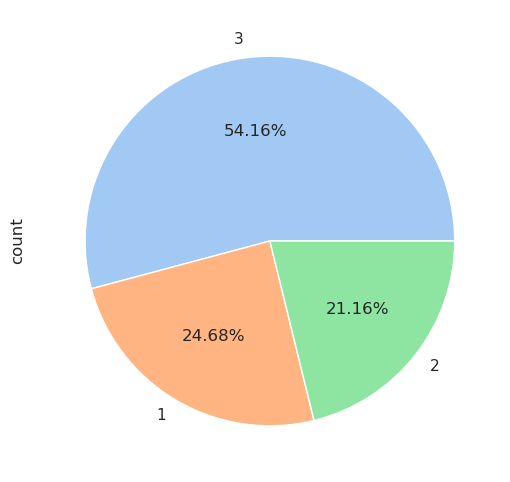

In [424]:
# Avec Pandas et dans un camembert
# ------------------------------
df['classe'].value_counts().plot(kind='pie', 
                                 autopct='%1.2f%%',
                                 # explode=[0.1]*len(df['classe'].unique())
                                 );

In [425]:
# Avec plotly.express 
# ------------------------------
px.pie(df, names='classe')

### Colonne `sexe`

Si nécessaire, la colonne `sexe` peut être au préalable transformée en une colonne numérique en utilisant la méthode `.replace()` ou encore en utilisant la méthode `.map()` ou `.astype().cat.codes`.

In [426]:
# Catégorisation de la variable 'sexe' en 'sexe_code'
# ===================================================
# df['sexe_code'] = df['sexe'].astype('category').cat.codes
# df['sexe_code'] = df['sexe'].map({'H':0, 'F':1})
# df['sexe_code'] = df['sexe'].replace({'H':0, 'F':1})

In [427]:
# Compte et le pourcentage de chaque catégorie
afficher_compte_et_pourcentage(df, 'sexe')

,Compte,Pourcentage (%)
sexe,,
H,843,64.4
F,466,35.6


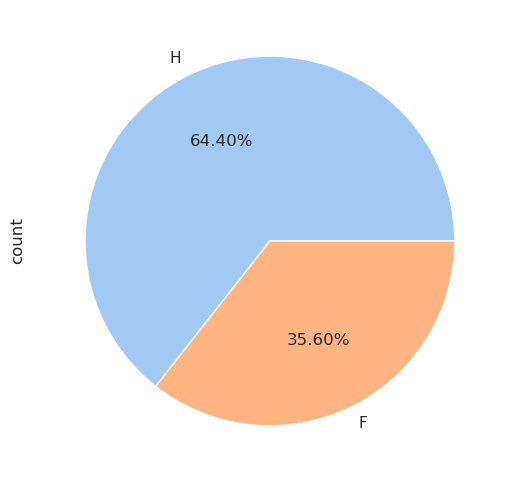

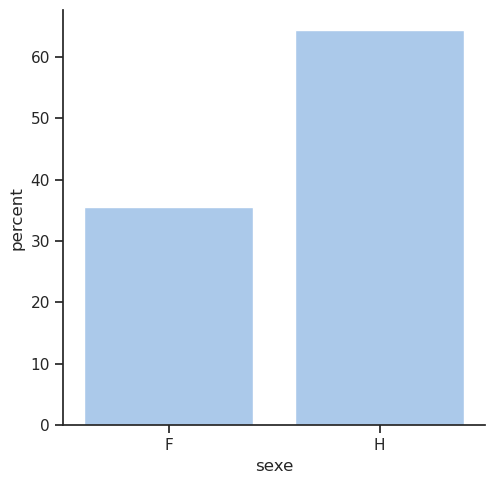

In [428]:
# Avec Pandas et dans un camembert
# ------------------------------
df['sexe'].value_counts().plot(kind='pie', autopct='%1.2f%%');

# Avec Seaborn
# ------------------------------
# 'catplot()': Figure-level interface for drawing categorical plots onto a FacetGrid.
# sns.catplot(x='sexe', data=df, kind='count');
sns.catplot(x='sexe', data=df, kind='count', stat='percent');

In [429]:
px.pie(df, names='sexe').show()
px.histogram(df, x='sexe', text_auto=True).show()

### Colonne `survivant`

In [430]:
# Compte et le pourcentage de chaque catégorie

afficher_compte_et_pourcentage(df, 'survivant')

,Compte,Pourcentage (%)
survivant,,
0,809,61.8
1,500,38.2


Seulement environ 38 % des personnes ont survécu. Existe-t-il un moyen de savoir quels types de personnes ont eu le plus de chances de survivre ? Y a-t-il des caractéristiques particulières partagées par les survivants ? Pour répondre à ces questions, nous examinerons plus tard les autres colonnes et leurs relations avec la colonne survivant.


In [431]:
# Barres : matplotlib ou seaborn

# df['survivant'].value_counts().plot(kind='bar');
# sns.countplot(data=df, x='survivant');

# df['survivant'].value_counts(normalize=True).plot(kind='bar');
# sns.countplot(data=df, x='survivant', stat='percent');
# sns.countplot(data=df, x='survivant', stat='proportion');

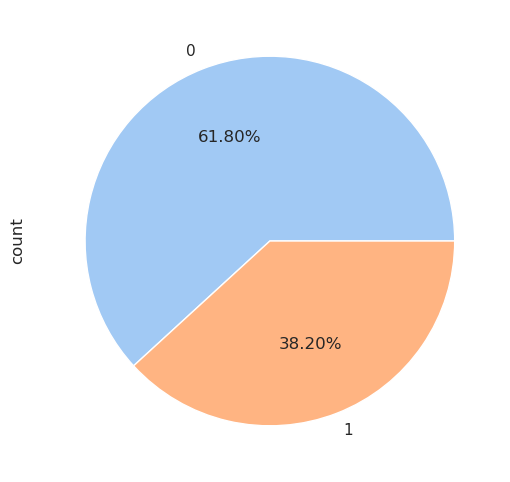

In [432]:
# Camembert : matplotlib pour afficher automatiquement les pourcentages
df['survivant'].value_counts().plot(kind='pie', autopct='%1.2f%%');

In [433]:
# px.pie(df, names='survivant')

# Mieux : chaque secteur affiche directement le nom (1 ou 0), le nombre d’occurrences et le pourcentage.
px.pie(df, 
       names='survivant', 
       color='survivant', 
       color_discrete_sequence=px.colors.qualitative.Pastel
       ).update_traces( texttemplate="%{label} : %{value} (%{percent})" ,
                        textposition="outside",    # texte à l’extérieur du secteur
                        pull=[0.05]*len(df['survivant'].unique()))  # léger décalage pour chaque secteur)

### Colonne `age`

Analysons d'abord les données numériques pour la colonne de l'âge. On peut choisir de n'afficher que certaines informations (par exemple, la moyenne et l'écart-type) en utilisant la méthode `.agg()` :

In [434]:
# df[['age']].describe()

# df[['age']].agg(['count','mean','median','std','min','max','nunique'])

# Mieux
def missing_percent(x):
    return x.isna().mean() * 100

df[['age']].agg({
    'age': ['count', missing_percent, 'mean', 'median', 'std', 'min', 'max', 'nunique']
}).rename(index={'missing_percent': 'missing_%'})



,age
count,1046.000000
missing_%,20.091673
mean,29.881135
median,28.000000
std,14.413500
min,0.166700
max,80.000000
nunique,98.000000


On peut afficher l'histogramme de la distribution de l'âge des passagers en utilisant le type de graphique `hist` de la fonction `.plot()` ou utiliser la fonction `histplot()` de Seaborn. Dans les deux cas on peut décider de regrouper les âges par intervalles de 10 ans en utilisant l'argument `bins` :

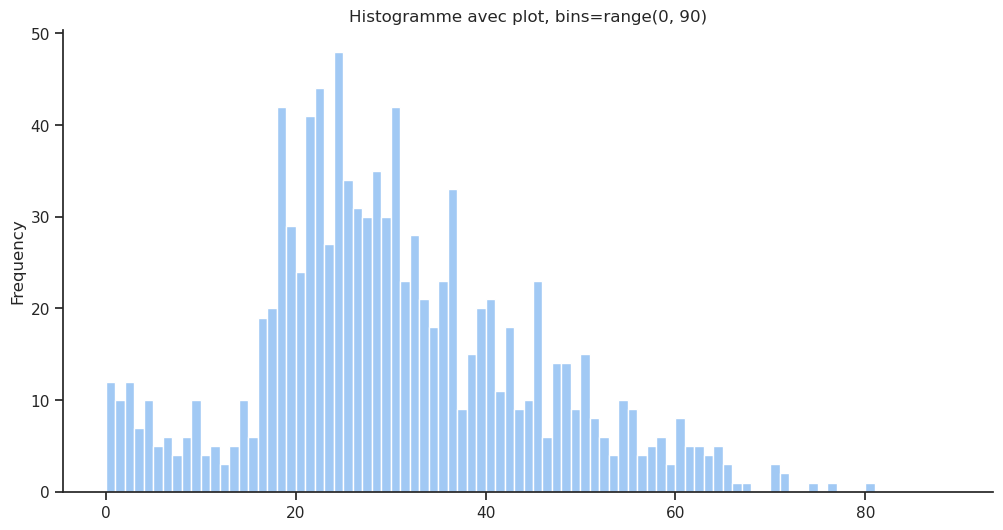

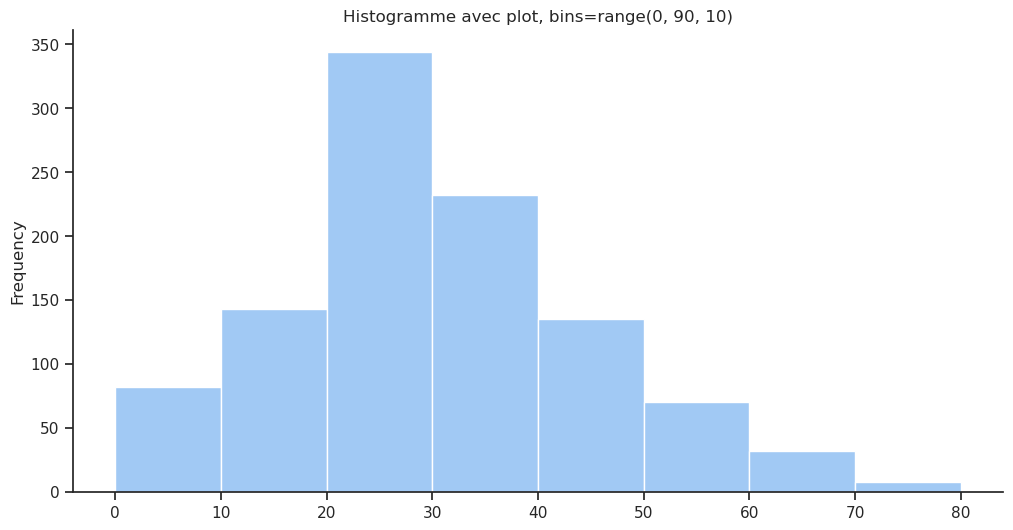

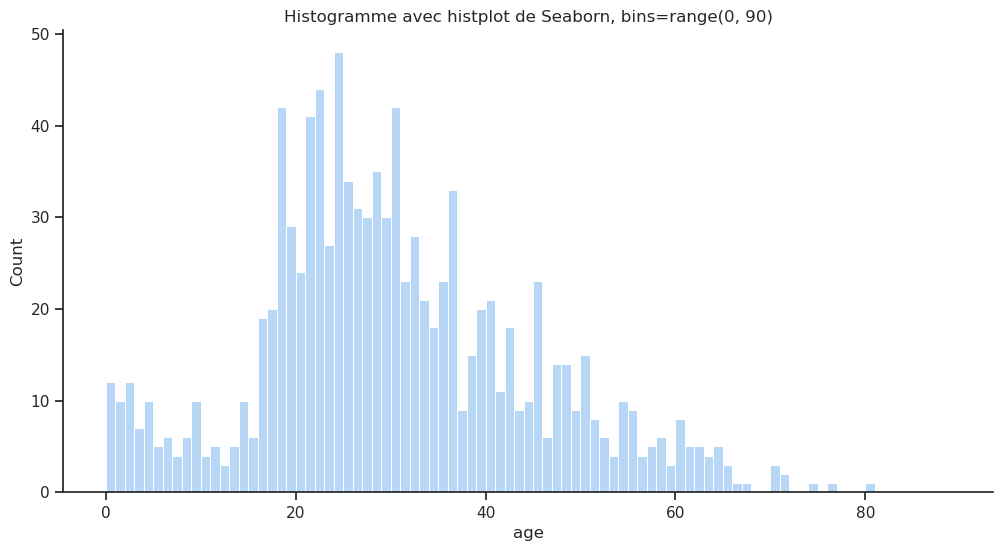

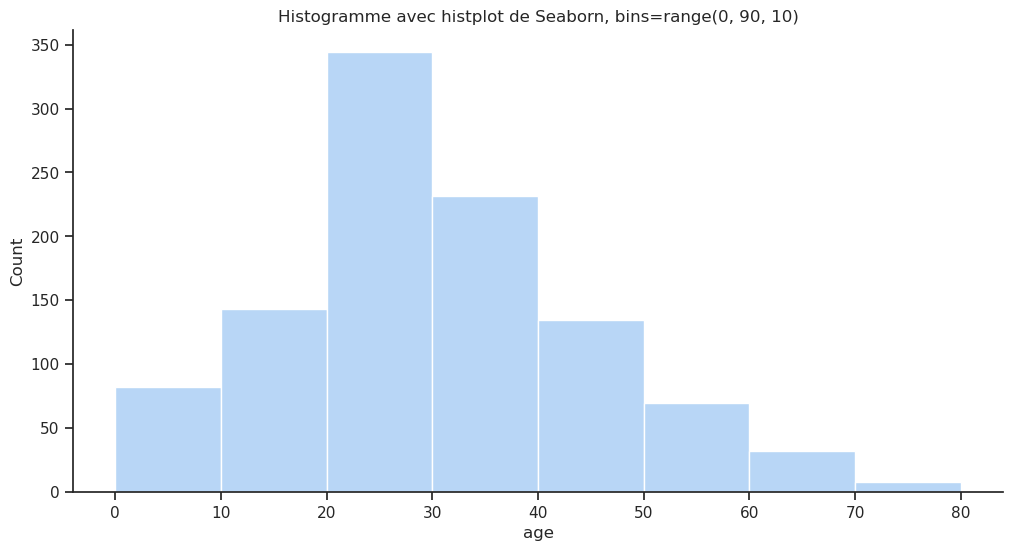

In [435]:
# Pandas
df['age'].plot(kind='hist',  bins=range(0, 90), edgecolor='white', title="Histogramme avec plot, bins=range(0, 90)");
plt.figure();
df['age'].plot(kind='hist', bins=range(0, 90, 10), edgecolor='white', title="Histogramme avec plot, bins=range(0, 90, 10)");

# Seaborn
plt.figure();
sns.histplot(data=df, x='age',  bins=range(0, 90));
plt.title("Histogramme avec histplot de Seaborn, bins=range(0, 90)");
plt.figure();
sns.histplot(df['age'], bins=range(0, 90, 10), edgecolor='white');
plt.title("Histogramme avec histplot de Seaborn, bins=range(0, 90, 10)");

In [436]:
# Avec plotly.express
# ------------------------------
px.histogram(df, x='age', nbins=90, title='Histogramme des âges').show()
# Pour des bins de 0 à 90 par pas de 10 il faut d'abord créer des groupes, on verra cela plus tard


On peut regrouper les données en découpant un ensemble de valeurs selon des intervalles, comme on l'a vu sur les graphiques précédents. Cela semble pertinent pour l'âge. On va donc ajouter une colonne `age_group` à notre DataFrame qui contiendra l'âge regroupé par intervalles de 10 ans. Pour cela,

1. on peut utiliser la méthode `pd.cut()` en spécifiant les valeurs à découper et les étiquettes des intervalles,

2. on peut passer à `pd.map()` une fonction que nous aurons définie pour regrouper les âges par intervalles de 10 ans.

In [437]:
# Première méthode

df['age_group'] = pd.cut(df['age'], bins=range(0, 90, 10), labels=[f'{i}-{i+10}' for i in range(0, 80, 10)])
df['age_group'] = df['age_group'].astype(str).replace('nan', 'Unknown')
df

,classe,survivant,sexe,age,prix,port_depart,age_group
0,1,1,F,29.0000,211.3375,S,20-30
1,1,1,H,0.9167,151.5500,S,0-10
2,1,0,F,2.0000,151.5500,S,0-10
3,1,0,H,30.0000,151.5500,S,20-30
4,1,0,F,25.0000,151.5500,S,20-30
...,...,...,...,...,...,...,...
1304,3,0,F,14.5000,14.4542,C,10-20
1305,3,0,F,NaN,14.4542,C,Unknown
1306,3,0,H,26.5000,7.2250,C,20-30
1307,3,0,H,27.0000,7.2250,C,20-30


In [438]:
# Deuxième méthode
# df['age_group'] = df['age'].map(lambda x: f'{int(x/10)*10}-{int(x/10)*10+10}' if not np.isnan(x) else 'Unknown')

In [439]:
# Compte et pourcentage de chaque catégorie (age_group)

afficher_compte_et_pourcentage(df, 'age_group')

,Compte,Pourcentage (%)
age_group,,
20-30,361,27.58
Unknown,263,20.09
30-40,210,16.04
10-20,162,12.38
40-50,132,10.08
0-10,86,6.57
50-60,62,4.74
60-70,27,2.06
70-80,6,0.46


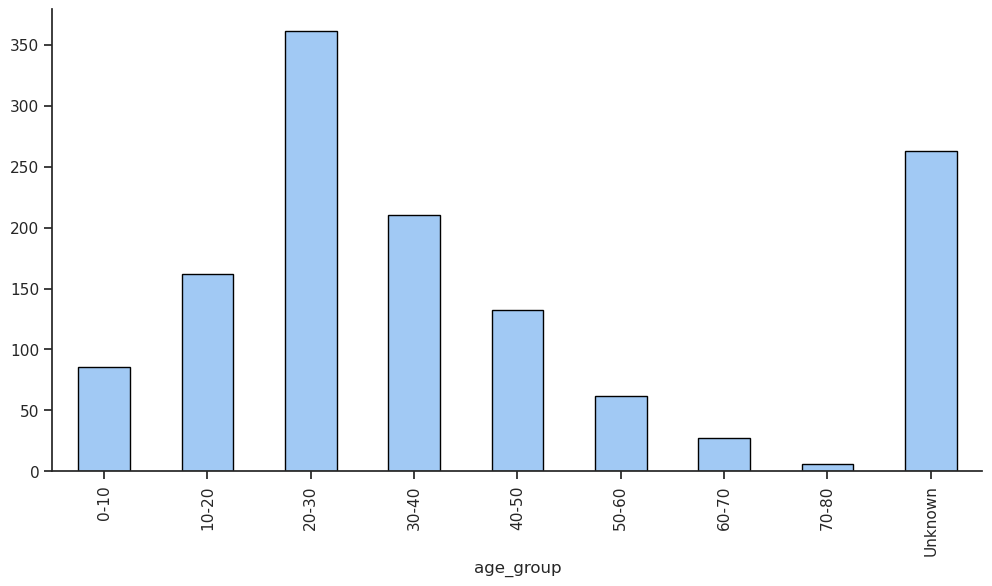

In [440]:
# Méthode 1 : Utiliser pandas pour créer un graphique en barres trié

# df['age_group'].plot(kind='bar', edgecolor='black'); # ne fonctionne pas car les valeurs sont catégorielles
# df['age_group'].value_counts().plot(kind='bar', edgecolor='black'); # ok mais pas trié par ordre croissant
df['age_group'].value_counts().sort_index().plot(kind='bar', edgecolor='black');

In [441]:
# Utiliser plotly.express
# ------------------------------
px.histogram(df, x='age_group', category_orders={'age_group': sorted(df['age_group'].unique())}, text_auto=True)

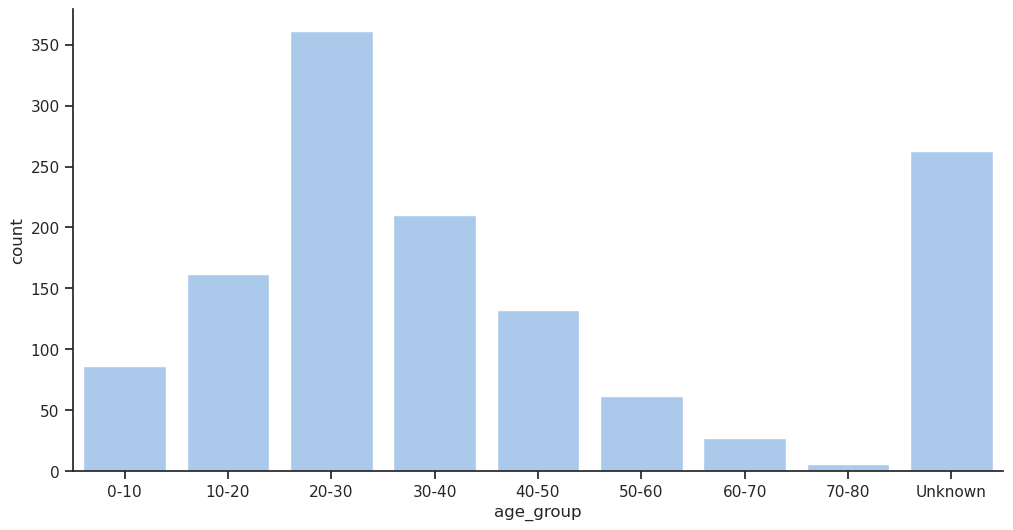

In [442]:
# Méthode 2 : Utiliser seaborn pour créer un countplot trié
sns.countplot(data=df, x='age_group', order=sorted(df['age_group'].unique()));

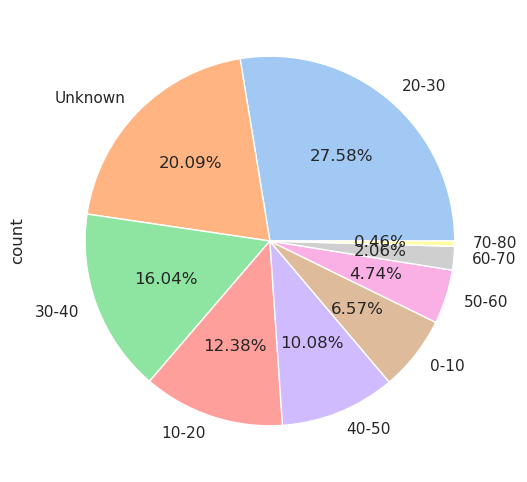

In [443]:
# Camembert : Pandas pour afficher automatiquement les pourcentages
df['age_group'].value_counts().plot(kind='pie', 
                                    autopct='%1.2f%%', 
                                    #explode=[0.1]*len(df['age_group'].unique())
                                    );

In [444]:
# Utiliser plotly.express
# ------------------------------

# px.pie(df, names='age_group')

# Mieux 
px.pie(df, 
       names='age_group', 
       color='age_group', 
       color_discrete_sequence=px.colors.qualitative.Pastel
       ).update_traces( texttemplate="%{label} : %{value} (%{percent})" ,
                        textposition="outside",    # texte à l’extérieur du secteur
                        pull=[0.05]*len(df['age_group'].unique()))  # léger décalage pour chaque secteur)

## Analyse de données combinées : liens entre deux ou plusieurs colonnes

Nous voulons consulter la colonne cible `survivant` pour voir combien de personnes ont survécu en fonction d'une autre variable, comme par exemple la classe, ou le sexe, ou l'age.

<div class="alert alert-info">

Dans cette partie nous allons utiliser les méthodes suivantes :

```python
.cross_tab()
.plot(kind='bar') .plot(kind='hist') .value_counts().plot(kind='pie')
sns.countplot() sns.histplot() sns.catplot()
```

</div>

### Lien entre 2 caractéristiques : la classe et les chances de survie

Observez la colonne `classe`. Il y a trois catégories dans cette colonne : les passagers de 1re classe, de 2e classe et de 3e classe représentés respectivement par les chiffres 1, 2 et 3. Nous nous attendrions à ce que les passagers de 1re classe aient eu la priorité pour monter à bord du navire et peut-être la priorité pour être sauvés dans les canots de sauvetage. Par conséquent, nous pourrions nous attendre à un taux de survie plus élevé des passagers de 1re classe par rapport à ceux de 2e ou 3e classe. Vérifions si c'est le cas.

La méthode `.crosstab()` permet de créer un tableau de contingence pour voir combien de personnes de chaque classe ont survécu ou non. 

In [445]:
pd.crosstab(df['classe'], df['survivant'], margins=True, margins_name='Total')

survivant,0,1,Total
classe,,,
1,123,200,323
2,158,119,277
3,528,181,709
Total,809,500,1309


Même résultat avec `.pivot_table()` :

- nous utilisons la fonction `size` pour compter le nombre d'occurrences dans chaque groupe.
- `fill_value=0` remplace les NaN par 0 dans la table (utile si certaines combinaisons de valeurs n'existent pas).

La fonction `pivot_table()` ne propose pas de manière directe pour ajouter des marges comme `crosstab()`.

In [446]:
pt = df.pivot_table(index='classe', columns='survivant', aggfunc='size', fill_value=0)
# Ajouter la ligne et la colonne des totaux
pt['Total'] = pt.sum(axis=1)  # Total par ligne
pt.loc['Total'] = pt.sum(axis=0)  # Total par colonne
pt

survivant,0,1,Total
classe,,,
1,123,200,323
2,158,119,277
3,528,181,709
Total,809,500,1309


On peut également afficher le **pourcentage de survie pour chaque classe** :

In [447]:
# Pourcentage par ligne
tc_cl_sur_norm = pd.crosstab(df['classe'], df['survivant'], margins=True, margins_name='Total', normalize='index')

# Pourcentage par colonne
# tc_cl_sur_norm = pd.crosstab(df['classe'], df['survivant'], margins=True, margins_name='Total', normalize='columns') 

# Pourcentage total
# tc_cl_sur_norm = pd.crosstab(df['classe'], df['survivant'], margins=True, margins_name='Total', normalize='all')

display(tc_cl_sur_norm)

survivant,0,1
classe,,
1,0.380805,0.619195
2,0.570397,0.429603
3,0.744711,0.255289
Total,0.618029,0.381971


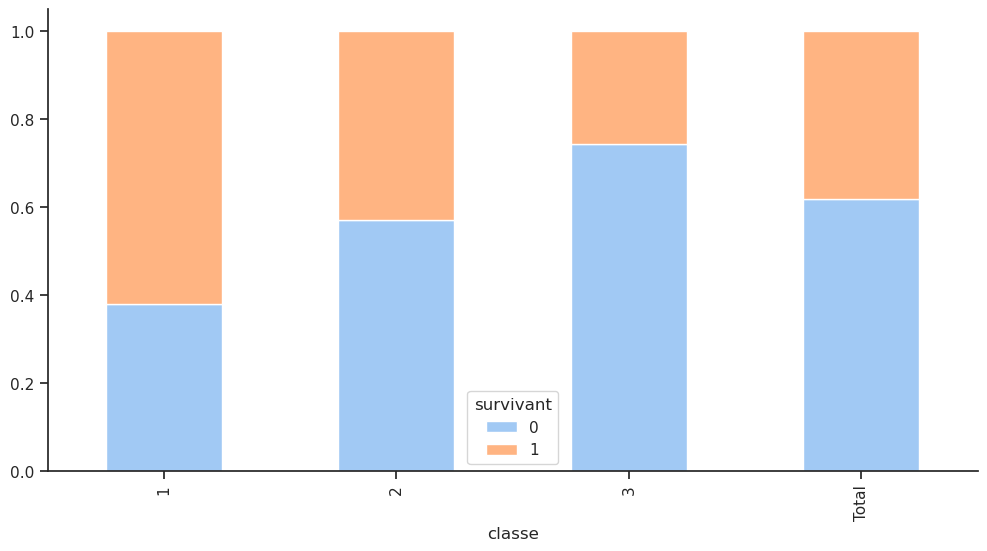

In [448]:
# Avec Pandas et dans un graphique en barres empilées
# --------------------------------------------------------------
tc_cl_sur_norm.plot(kind='bar', stacked=True);

# NB Normalisation par ligne : chaque barre a la même hauteur (1 ou 100%) 
# et les segments représentent la proportion de survivants dans chaque classe.

# On ne peut pas faire cela avec plotly.express directement.

Ce graphique en barres indique un taux de survie supérieur à 60 % pour les passagers de 1re classe, inférieur à 50 % pour les passagers de 2e classe et seulement environ 25 % pour les passagers de 3e classe, même s'ils étaient majoritaires. Il s'agit d'une étude informelle non rigoureuse utilisant des outils de visualisation de données pour confirmer que le taux de survie est lié à la classe des passagers.

**Remarque** : il faut être prudent lors de l'interprétation de ce graphique, car les pourcentages indiquent uniquement le pourcentage de survivants pour chaque classe de passagers, et non le pourcentage de survivants parmi tous les passagers. Par exemple, si 100 passagers de 1re classe ont survécu, cela ne signifie pas que 60 % de tous les passagers ont survécu. Cela signifie que 60 % des passagers de 1re classe ont survécu. Voici le graphe avec des pourcentages de survie parmi tous les passagers :

In [449]:
# Pourcentage total
tc_cl_sur_norm = pd.crosstab(df['classe'], df['survivant'], margins=False, margins_name='Total', normalize='all')

display(tc_cl_sur_norm)

survivant,0,1
classe,,
1,0.093965,0.152788
2,0.120703,0.090909
3,0.403361,0.138273


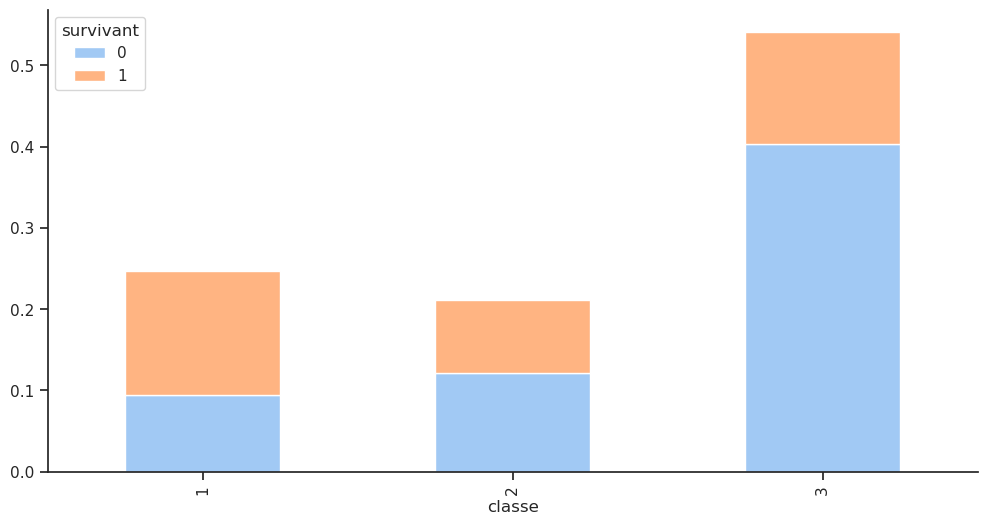

In [450]:
tc_cl_sur_norm.plot(kind='bar', stacked=True);

Quel graphe est le plus pertinent pour comparer les survivants et les non-survivants en fonction de la classe ?

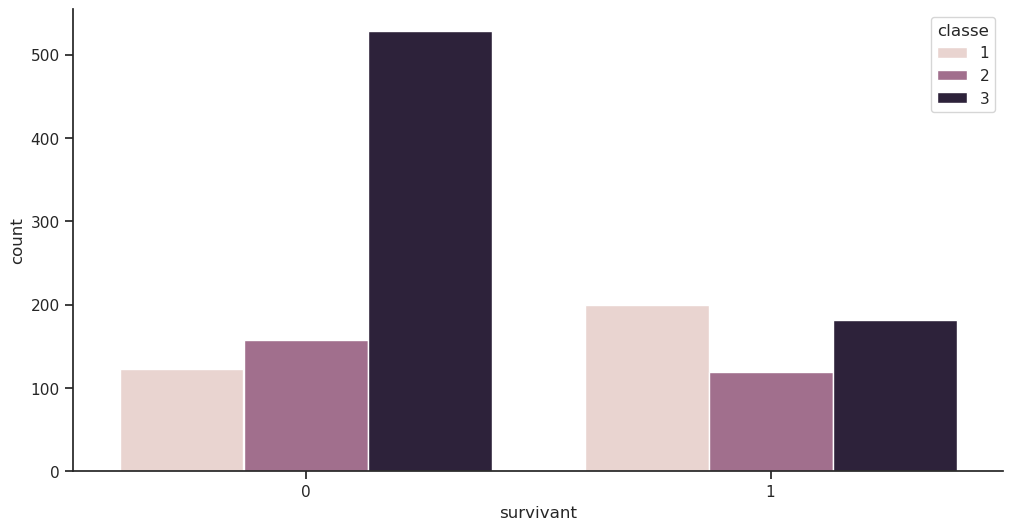

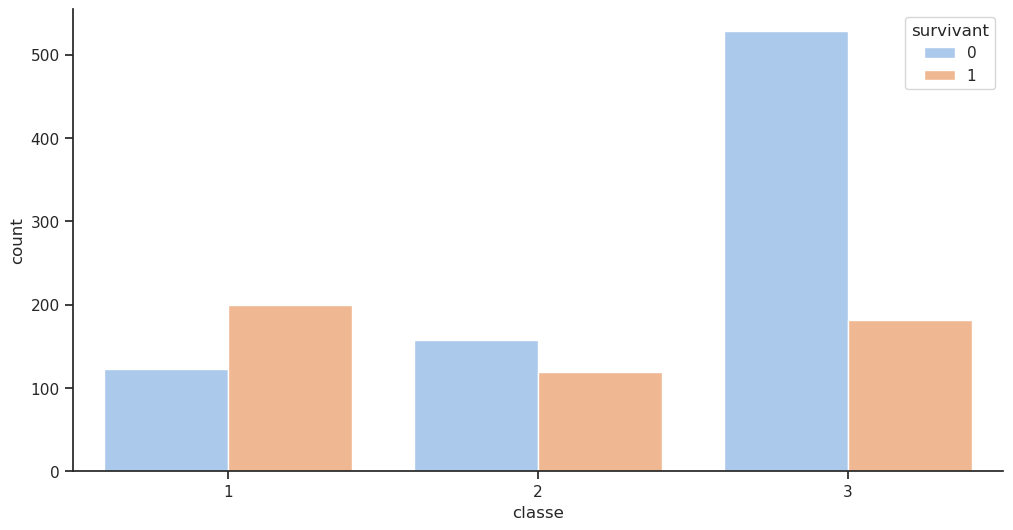

In [451]:
# Quel graphe est le plus pertinent pour comparer les survivants et les non-survivants en fonction de la classe ?
# ===============================================================================================================

# sns.countplot(data=df, x='survivant')

# plt.figure();
# Chaque statut (survivant / décédé) est divisé en trois barres (classe 1, 2, 3)
sns.countplot(data=df, x='survivant', hue='classe');

plt.figure();
# Chaque classe est divisée en deux barres (survivant et non-survivant)
sns.countplot(data=df, x='classe', hue='survivant');

# plt.figure();
# sns.histplot(data=df, x='classe', hue='survivant', multiple='stack'); # idem empilées

In [452]:
px.histogram(df, x='survivant', color='classe', barmode='group', text_auto=True).show()

px.histogram(df, x='classe', color='survivant', barmode='group', text_auto=True).show()

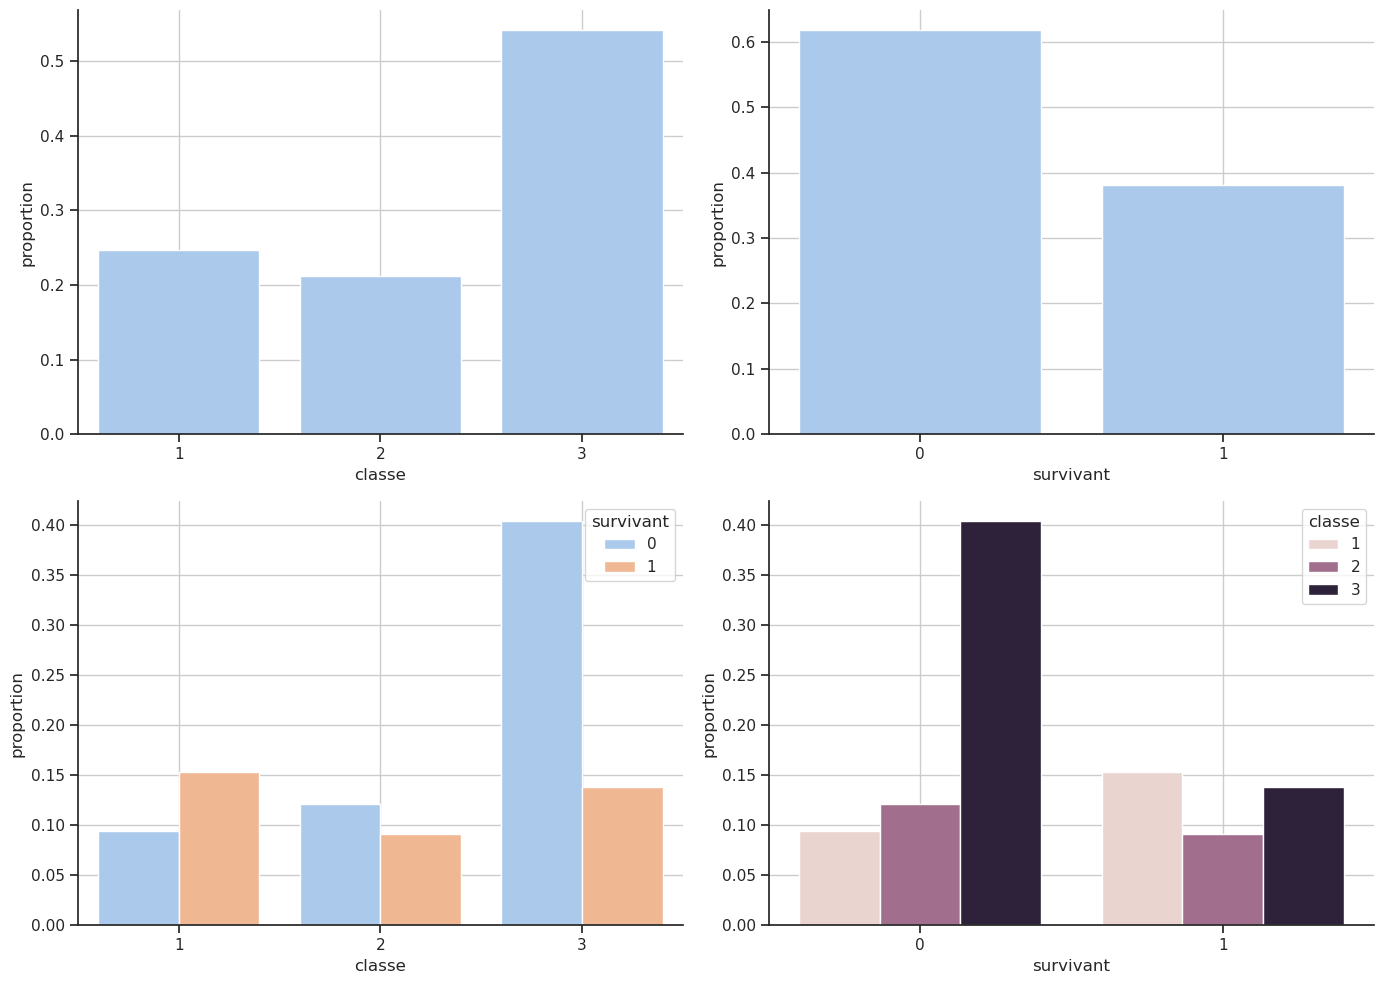

In [453]:
# Taille de la figure et disposition
rows, cols = 2, 2
fig, axx = plt.subplots(rows, cols, figsize=(14, 10))
axx = axx.flatten()  # Pour accéder facilement aux axes

# Proportion par classe
sns.countplot(data=df, x='classe', stat='proportion', ax=axx[0])
axx[0].grid()

# Proportion par survivant
sns.countplot(data=df, x='survivant', stat='proportion', ax=axx[1])
axx[1].grid()

# Classe par survivant
sns.countplot(data=df, x='classe', hue='survivant', stat='proportion', ax=axx[2])
# sns.histplot(data=df, x='classe', hue='survivant', stat='proportion', multiple='stack', ax=axx[2])
axx[2].grid()

# Survivant par classe
sns.countplot(data=df, x='survivant', hue='classe', stat='proportion', ax=axx[3])
# sns.histplot(data=df, x='survivant', hue='classe', stat='proportion', multiple='stack', ax=axx[3])
axx[3].grid()



# Ajuster l'espacement
plt.tight_layout()
plt.show()


In [454]:
# import plotly.graph_objects as go

# fig = make_subplots(
#     rows=2, cols=2,
#     subplot_titles=(
#         "Proportion par classe",
#         "Proportion par survivant",
#         "Classe par survivant",
#         "Survivant par classe",
#     )
# )

# # Proportion par classe
# tc_cl = df['classe'].value_counts().sort_index()
# tc_cl_norm = tc_cl / tc_cl.sum()
# fig.add_trace(go.Bar(
#     x=tc_cl.index,
#     y=tc_cl_norm.values,
#     text=[f"{label}: {val} ({pct:.2%})" for label, val, pct in zip(tc_cl.index, tc_cl.values, tc_cl_norm.values)],
#     textposition="inside",
#     showlegend=False
# ), row=1, col=1)

# # Proportion par survivant
# tc_surv = df['survivant'].value_counts().sort_index()
# tc_surv_norm = tc_surv / tc_surv.sum()
# fig.add_trace(go.Bar(
#     x=tc_surv.index,
#     y=tc_surv_norm.values,
#     text=[f"{label}: {val} ({pct:.2%})" for label, val, pct in zip(tc_surv.index, tc_surv.values, tc_surv_norm.values)],
#     textposition="inside",
#     showlegend=False
# ), row=1, col=2)

# # Classe par survivant (empilé)
# tc_cl_surv = pd.crosstab(df['classe'], df['survivant'])
# tc_cl_surv_norm = tc_cl_surv.div(tc_cl_surv.sum(axis=1), axis=0)
# for col in tc_cl_surv.columns:
#     fig.add_trace(go.Bar(
#         x=tc_cl_surv.index,
#         y=tc_cl_surv_norm[col],
#         text=[f"{col}: {val} ({pct:.2%})" for val, pct in zip(tc_cl_surv[col], tc_cl_surv_norm[col])],
#         textposition="inside",
#         showlegend=False
#     ), row=2, col=1)

# # Survivant par classe (empilé)
# tc_surv_cl = pd.crosstab(df['survivant'], df['classe'])
# tc_surv_cl_norm = tc_surv_cl.div(tc_surv_cl.sum(axis=1), axis=0)
# for col in tc_surv_cl.columns:
#     fig.add_trace(go.Bar(
#         x=tc_surv_cl.index,
#         y=tc_surv_cl_norm[col],
#         text=[f"{col}: {val} ({pct:.2%})" for val, pct in zip(tc_surv_cl[col], tc_surv_cl_norm[col])],
#         textposition="inside",
#         showlegend=False
#     ), row=2, col=2)

# fig.update_layout(
#     height=800,
#     width=1000,
#     barmode='stack'
# )

# fig.show()


Nous allons généraliser cette approche en créant une fonction qui prend en argument une colonne et affiche le taux de survie pour chaque catégorie unique dans cette colonne, ainsi que les deux tableaux de contingence.

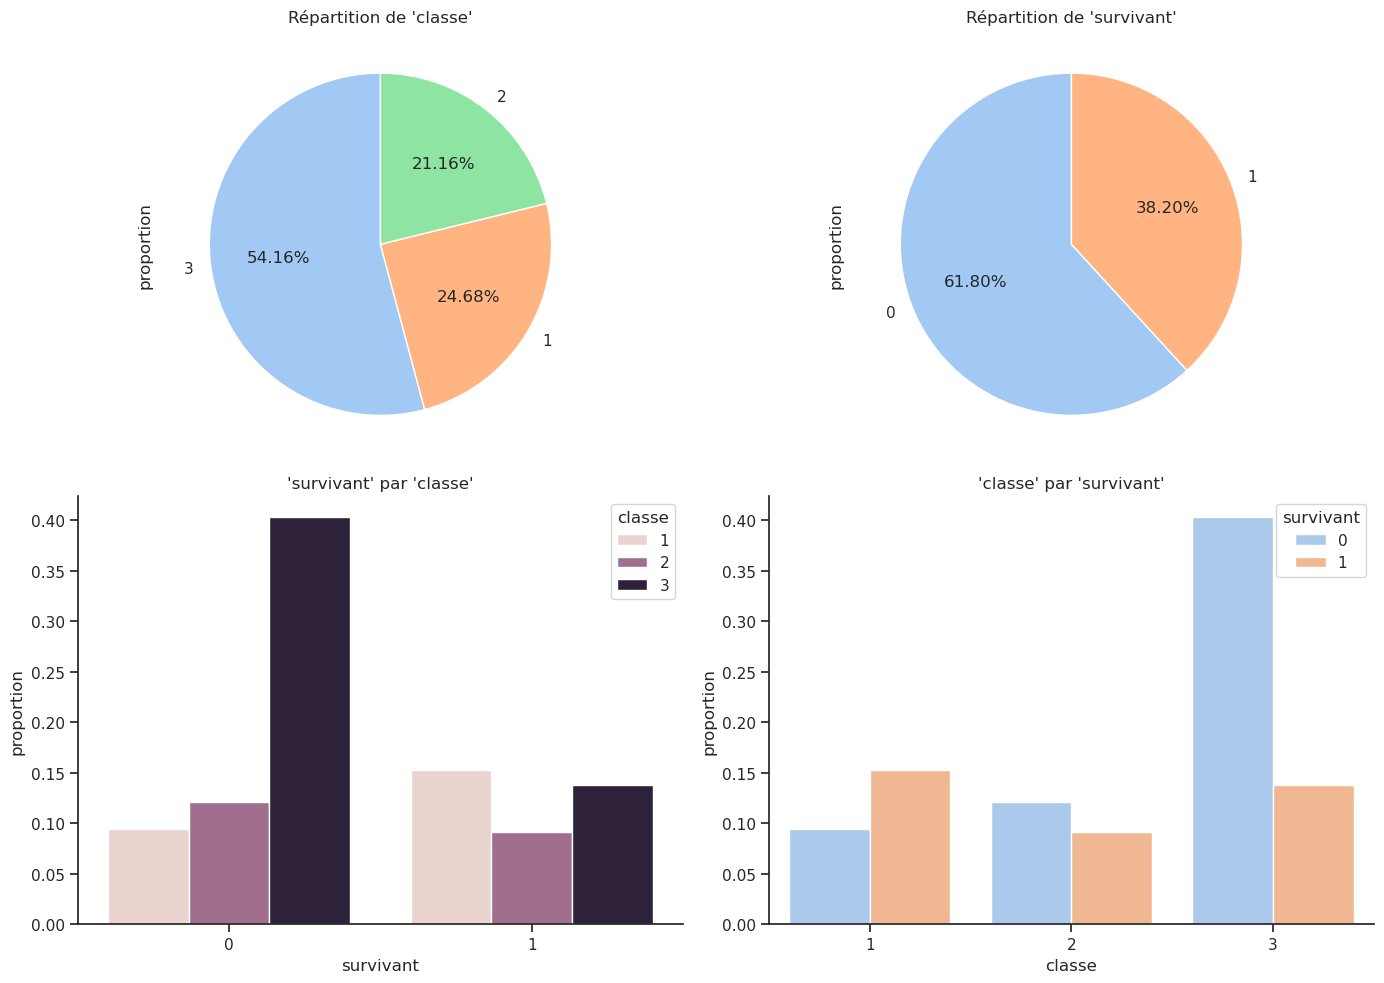

Crosstab absolu :

survivant,0,1,Total
classe,,,
1,123,200,323
2,158,119,277
3,528,181,709
Total,809,500,1309


Crosstab normalisé par ligne :

survivant,0,1
classe,,
1,0.380805,0.619195
2,0.570397,0.429603
3,0.744711,0.255289
Total,0.618029,0.381971


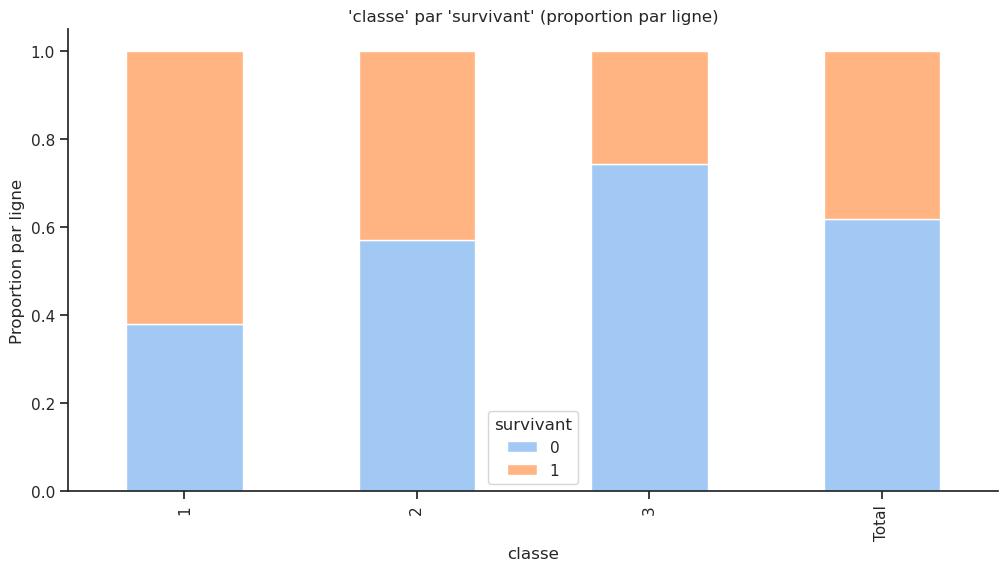

In [455]:
def plot_proportions(df, col1, col2):
    plt.figure(figsize=(14, 10))
    
    # Pie chart col1
    plt.subplot(2, 2, 1)
    df[col1].value_counts(normalize=True).plot(
        kind='pie', autopct='%1.2f%%', startangle=90, legend=False
    )
    plt.title(f"Répartition de '{col1}'")
    
    # Pie chart col2
    plt.subplot(2, 2, 2)
    df[col2].value_counts(normalize=True).plot(
        kind='pie', autopct='%1.2f%%', startangle=90, legend=False
    )
    plt.title(f"Répartition de '{col2}'")
    
    # Bar plot col2 par col1 (proportion)
    plt.subplot(2, 2, 3)
    sns.countplot(data=df, x=col2, hue=col1, stat='proportion')
    plt.title(f"'{col2}' par '{col1}'")
    
    # Bar plot col1 par col2 (proportion)
    plt.subplot(2, 2, 4)
    sns.countplot(data=df, x=col1, hue=col2, stat='proportion')
    plt.title(f"'{col1}' par '{col2}'")
    
    plt.tight_layout()
    plt.show()

    # Crosstabs
    tc = pd.crosstab(df[col1], df[col2], margins=True, margins_name='Total') # pourcentage total
    tc_norm = pd.crosstab(df[col1], df[col2], margins=True, margins_name='Total', normalize='index') # pourcentage par ligne
    # tc_norm_all = pd.crosstab(df[col1], df[col2], margins=True, normalize='all') # pourcentage total

    display(Markdown("Crosstab absolu :"))
    display(tc)
    display(Markdown("Crosstab normalisé par ligne :"))
    display(tc_norm)
    
    # Bar plot empilé du crosstab normalisé
    tc_norm.plot(kind='bar', stacked=True)
    plt.ylabel("Proportion par ligne")
    plt.title(f"'{col1}' par '{col2}' (proportion par ligne)")
    plt.show()


# TEST
plot_proportions(df, 'classe', 'survivant')

### Lien entre 2 caractéristiques : le sexe et les chances de survie

Nous menons une enquête similaire pour la colonne `sexe`. L'article de Wikipédia sur le RMS Titanic indiquait que « le protocole "les femmes et les enfants d'abord" était généralement suivi lors du chargement des canots de sauvetage ». Nous pouvions donc nous attendre à un taux de survie plus élevé pour les femmes et les enfants. Vérifions si cela est vrai.

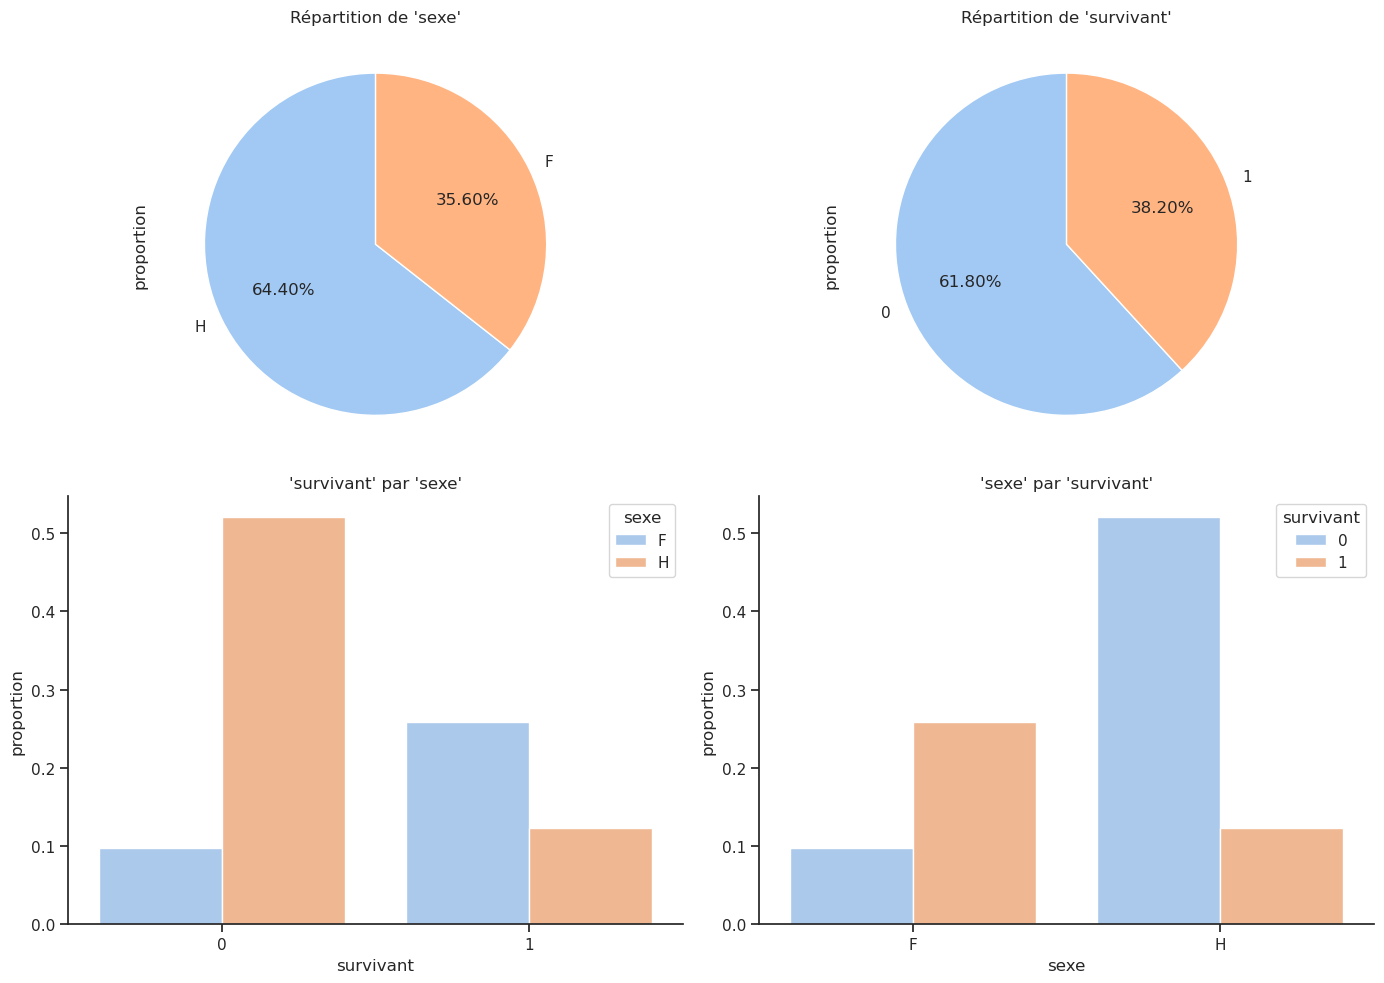

Crosstab absolu :

survivant,0,1,Total
sexe,,,
F,127,339,466
H,682,161,843
Total,809,500,1309


Crosstab normalisé par ligne :

survivant,0,1
sexe,,
F,0.272532,0.727468
H,0.809015,0.190985
Total,0.618029,0.381971


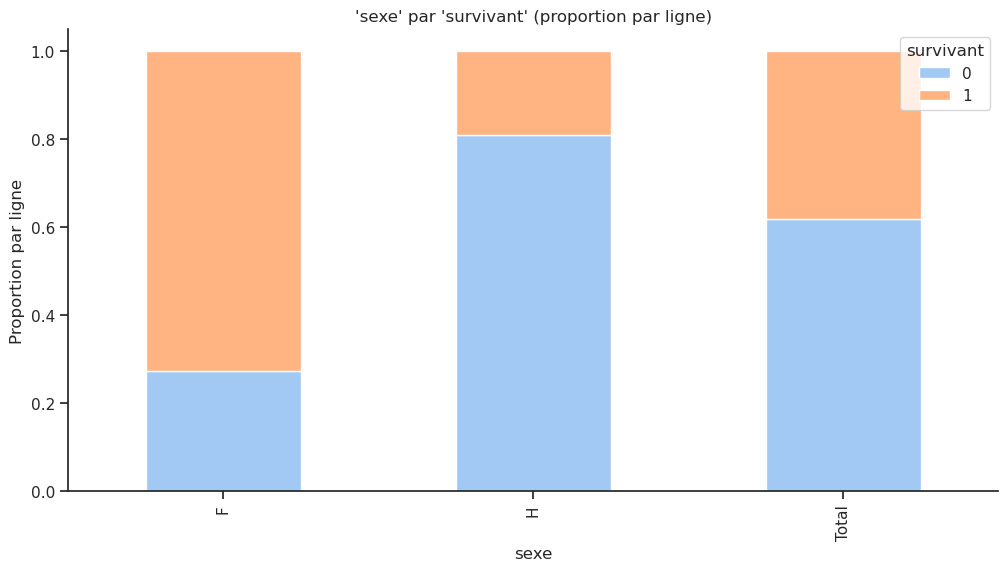

In [456]:
plot_proportions(df, 'sexe', 'survivant')

Parmi les femmes, la majorité a survécu, avec un taux de survie de 75 %, contre un taux de survie de 20 % pour les hommes.

### Lien entre 2 caractéristiques : le port de départ et les chances de survie

La dernière caractéristique catégorique que nous pouvons examiner est le port d'embarquement. Les passagers ont embarqué depuis trois ports différents nommés Cherbourg, Queenstown et Southampton, abrégés respectivement par les lettres C, Q et S. Nous avons déjà vu que le sexe et la classe influencent le taux de survie des passagers. Le port d'embarquement influence-t-il la survie ? 

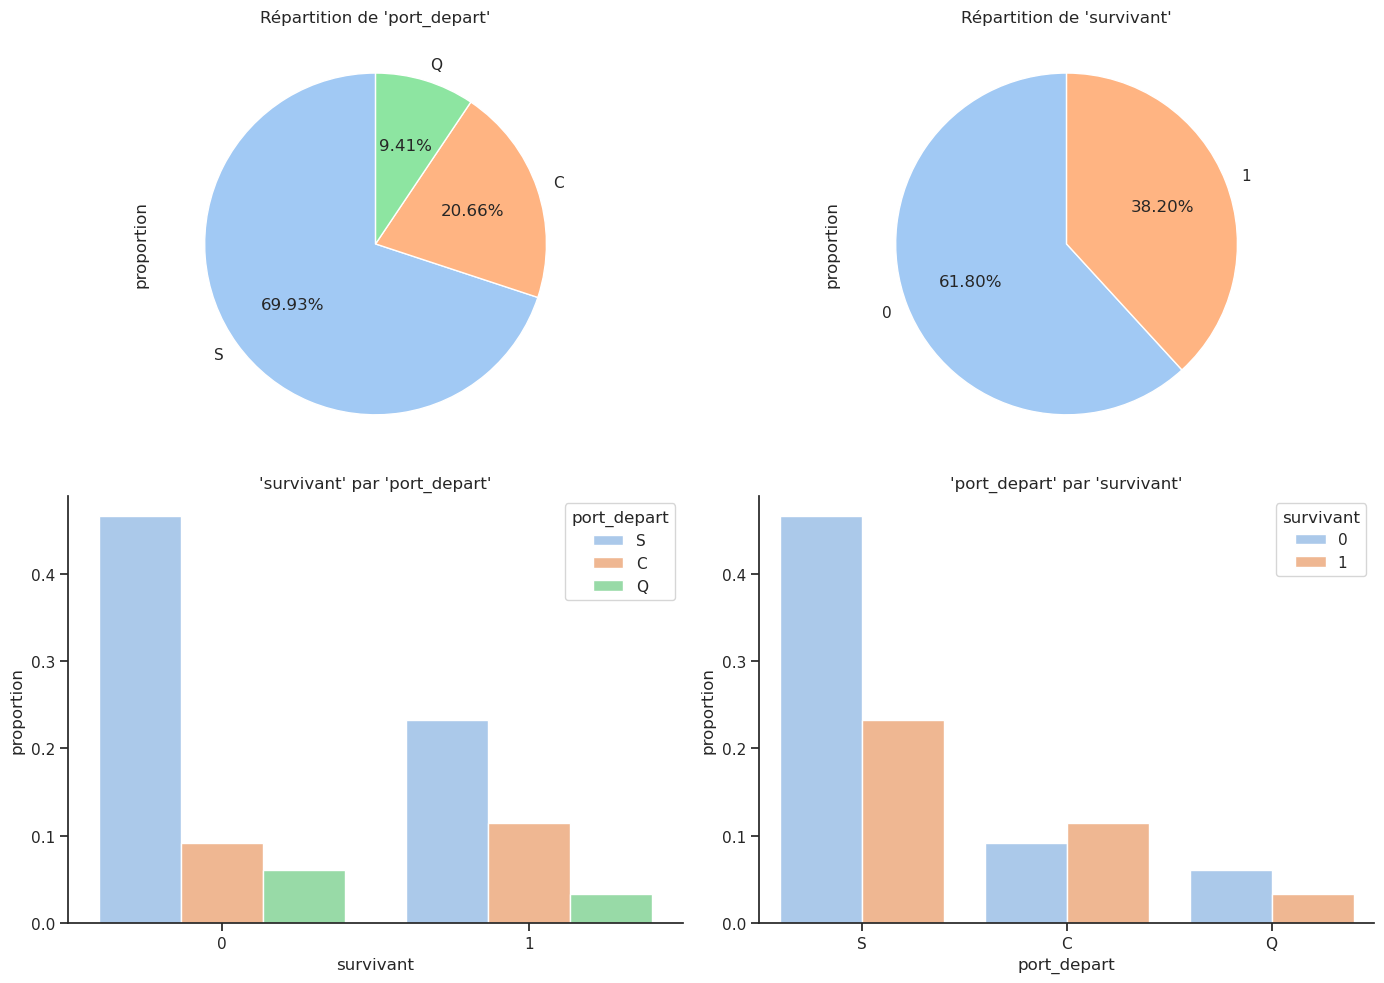

Crosstab absolu :

survivant,0,1,Total
port_depart,,,
C,120,150,270
Q,79,44,123
S,610,304,914
Total,809,498,1307


Crosstab normalisé par ligne :

survivant,0,1
port_depart,,
C,0.444444,0.555556
Q,0.642276,0.357724
S,0.667396,0.332604
Total,0.618975,0.381025


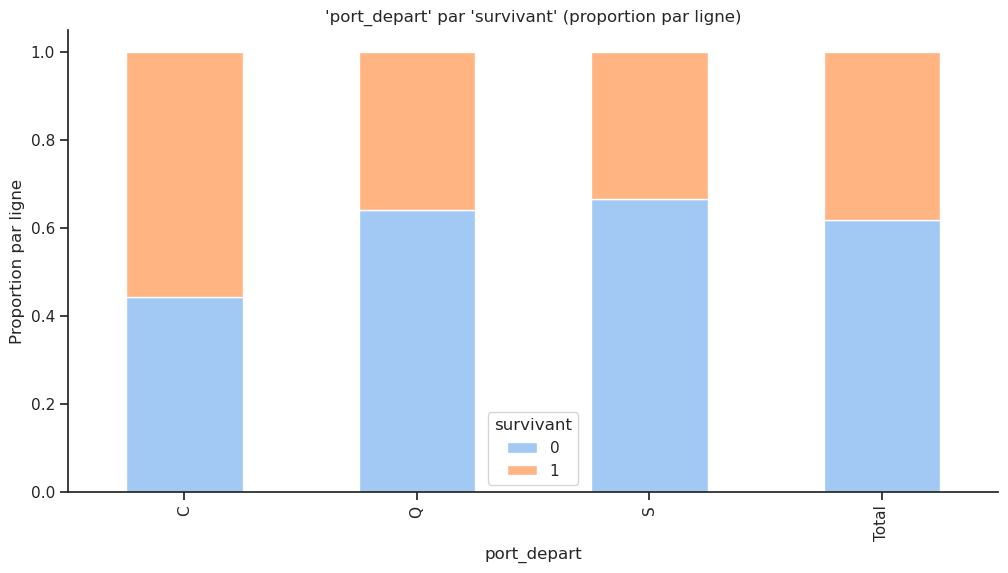

In [457]:
plot_proportions(df, 'port_depart', 'survivant')

D'après ces graphiques, environ 70 % des passagers ont embarqué depuis S(outhampton), 20 % depuis C(herbourg) et 10 % depuis Q(ueenstown). Cependant, le taux de survie le plus élevé, soit 55 %, est obtenu pour les passagers ayant embarqué à Cherbourg, puis environ 35 % à Queenstown et 30 % à Southampton. 

### Lien entre 2 caractéristiques : l'age et la classe

Quelle est la distribution de l'âge des passagers en fonction de la classe ?

In [458]:
# df.groupby('classe')['age'].mean()
df.pivot_table(values='age', index='classe', aggfunc='mean')

,age
classe,
1,39.159918
2,29.506705
3,24.816367


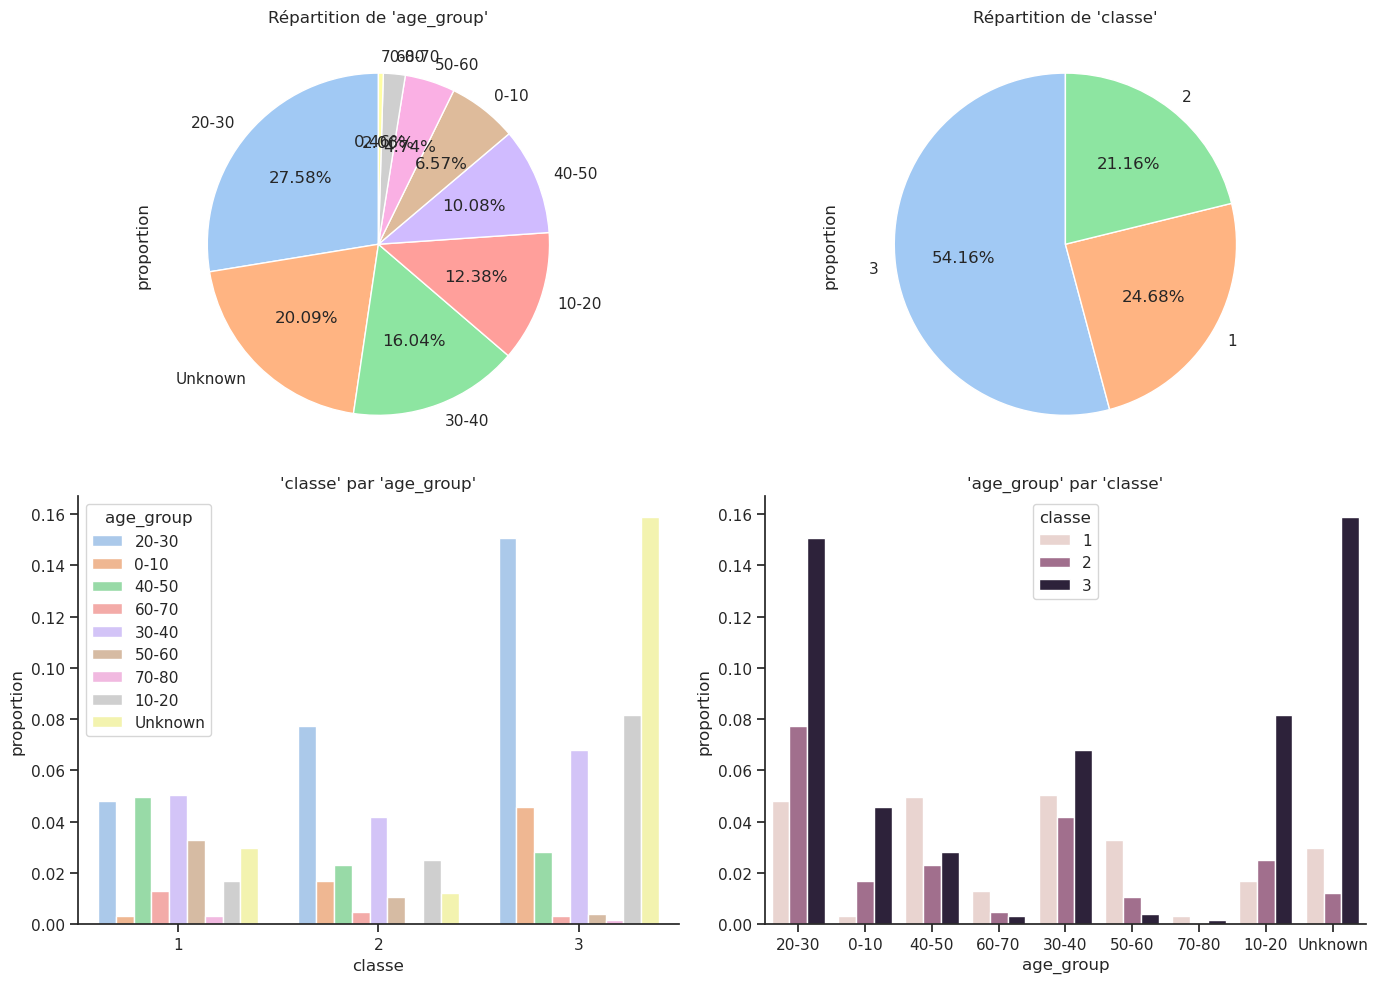

Crosstab absolu :

classe,1,2,3,Total
age_group,,,,
0-10,4,22,60,86
10-20,22,33,107,162
20-30,63,101,197,361
30-40,66,55,89,210
40-50,65,30,37,132
50-60,43,14,5,62
60-70,17,6,4,27
70-80,4,0,2,6
Unknown,39,16,208,263


Crosstab normalisé par ligne :

classe,1,2,3
age_group,,,
0-10,0.046512,0.255814,0.697674
10-20,0.135802,0.203704,0.660494
20-30,0.174515,0.279778,0.545706
30-40,0.314286,0.261905,0.423810
40-50,0.492424,0.227273,0.280303
50-60,0.693548,0.225806,0.080645
60-70,0.629630,0.222222,0.148148
70-80,0.666667,0.000000,0.333333
Unknown,0.148289,0.060837,0.790875


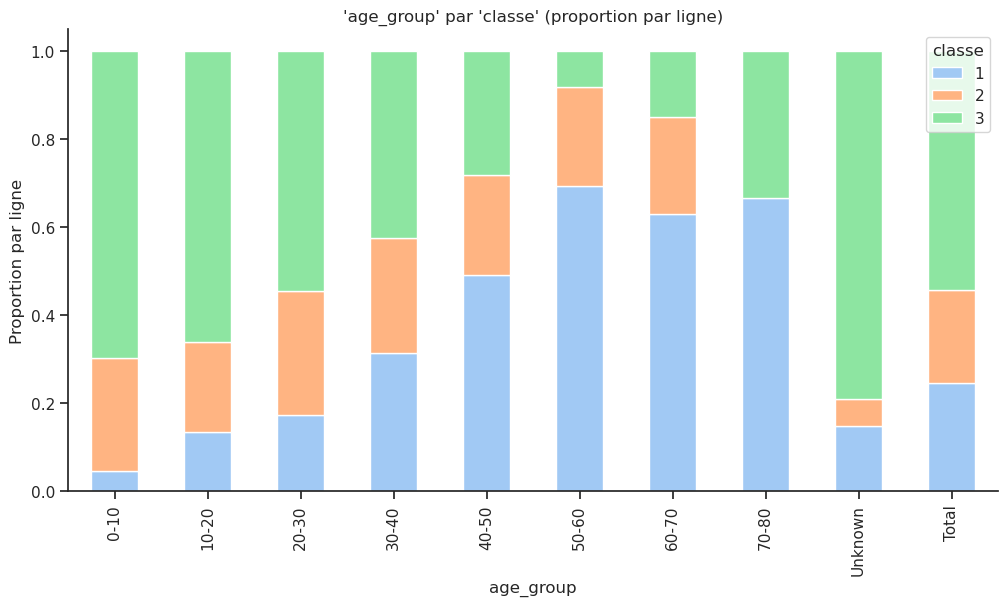

In [459]:
plot_proportions(df, 'age_group', 'classe')

### Bonus : nouvelle colonne femmes / hommes / enfants

Il pourrait être utile de connaître la répartition entre les hommes, les femmes et les enfants. Pour cela, nous allons créer une nouvelle colonne `personne` qui prendra les valeurs `homme`, `femme` ou `enfant` en fonction de l'âge. 
Nous allons ensuite afficher le taux de survie pour chaque catégorie de personnes.

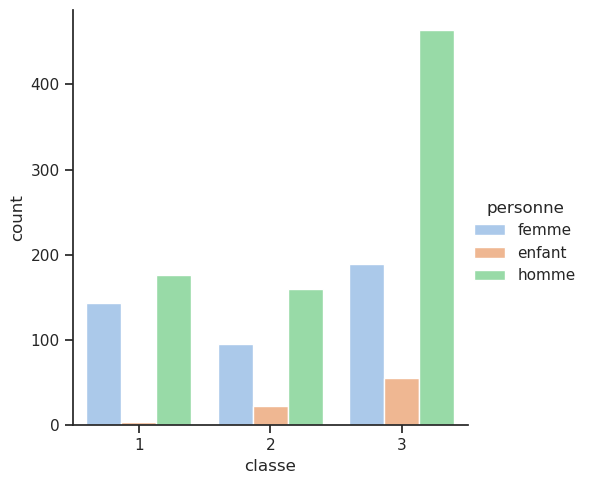

In [460]:
df['personne'] = df['sexe']
df['personne'] = df['personne'].replace({'H':'homme', 'F':'femme'})
df.loc[df['age']<10, 'personne'] = 'enfant'

sns.catplot(x='classe', data=df, hue='personne', kind='count');

# sns.catplot(x='classe', y='survivant', data=df, hue='personne', kind='point')

In [461]:
px.histogram(df, x='classe', color='personne', text_auto=True)

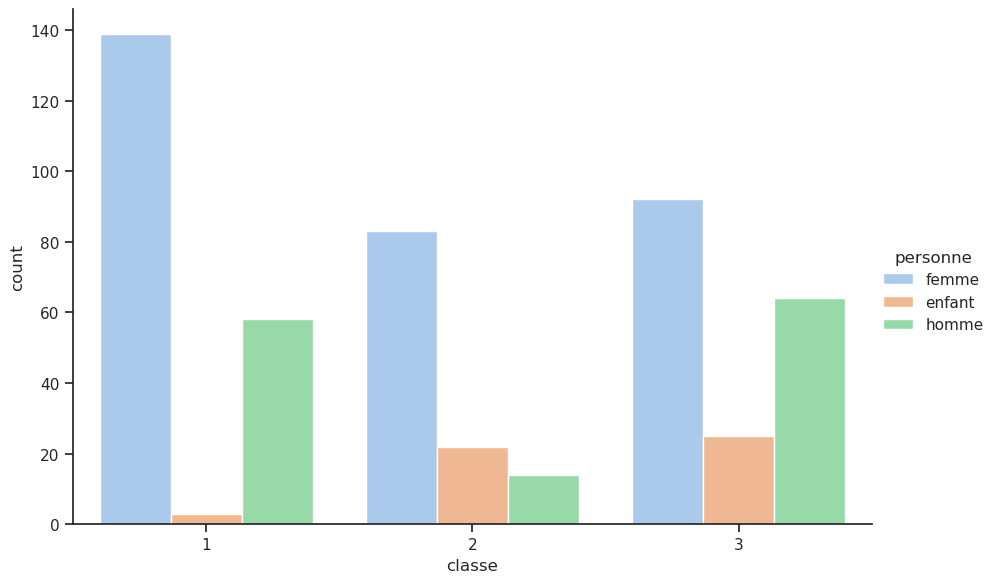

In [462]:
# Graphique pour le nombre absolu de survivants
sns.catplot(
    x='classe', 
    hue='personne', 
    data=df[df['survivant'] == 1], 
    kind='count', 
    height=6, 
    aspect=1.5
);

In [463]:
df_survivants = df[df['survivant'] == 1]
px.histogram(df_survivants, x='classe', color='personne', text_auto=True)

### Lien entre 3 caractéristiques : la classe, l'âge et les chances de survie

Nous souhaitons analyser comment une variable continue (comme l'âge) varie au sein de groupes catégoriels (comme la classe), tout en distinguant les sous-groupes à l'intérieur de chaque catégorie à l'aide d'une variable de différenciation (ici, le statut de survivant). Ce type de graphique permet d'avoir une vue claire des distributions, de voir si certaines catégories ont des valeurs extrêmes ou des tendances particulières, et de faire des comparaisons entre des groupes sous différents critères.

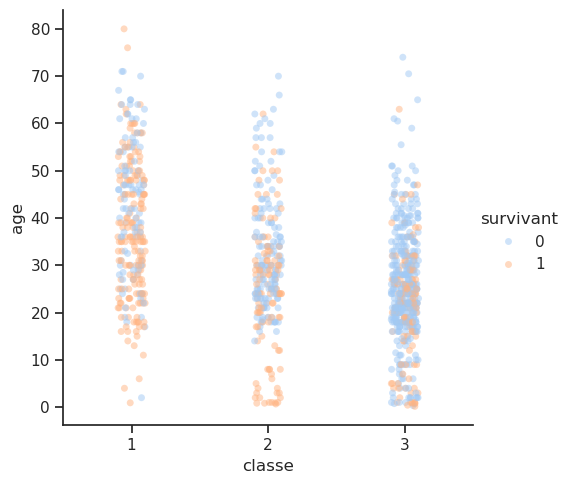

In [464]:
# cat pour categorical, comme la variable 'classe'
sns.catplot(data=df, x='classe', y='age', hue='survivant', alpha=0.5);

In [465]:
px.strip(df, x='classe', y='age', color='survivant')

### Lien entre 3 caractéristiques : le sexe, l'âge et les chances de survie

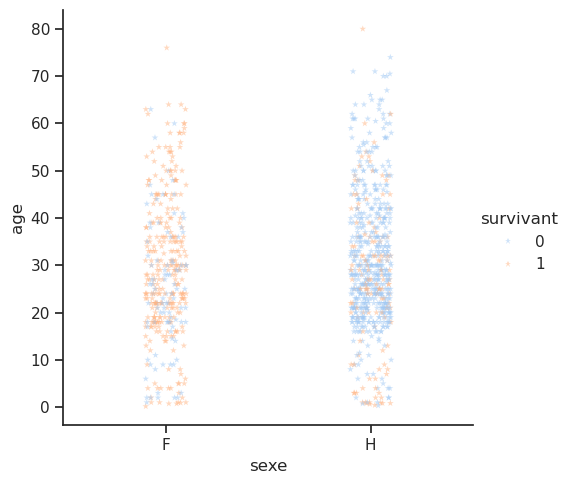

In [466]:
# cat pour categorical, comme la variable 'sexe'
sns.catplot(data=df, x='sexe', y='age', hue='survivant', marker="*", alpha=0.5);

In [467]:
px.strip(df, x='sexe', y='age', color='survivant')

### Lien entre 3 caractéristiques : le prix, l'age et les chances de survie

La fonction `relplot()` est utilisée pour créer des graphiques de relations entre deux variables continues et étudier des différences entre groupes. Ici on veut voir si les tendances observées entre prix et âge diffèrent selon le statut de survie.

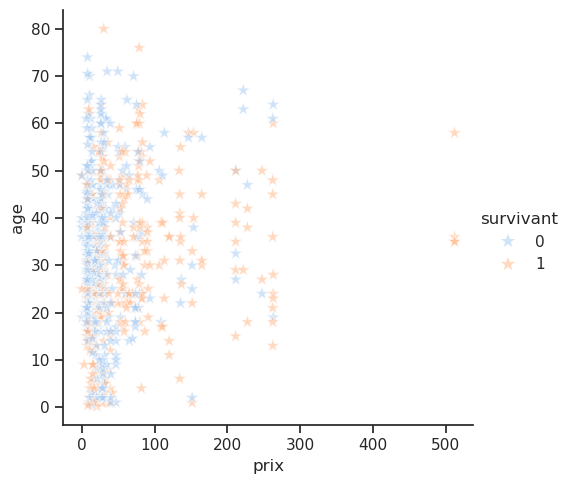

In [468]:
# rel pour relationship
sns.relplot(data=df, x='prix', y='age', hue='survivant', marker="*", s=100, alpha=0.5);

In [469]:
px.scatter(df, x='prix', y='age', color='survivant', opacity=0.5)

La fonction `jointplot` ajoute des informations sur leurs distributions respectives sur les bords du graphique (grâce à des histogrammes ou des KDEs). 

<Figure size 1200x600 with 0 Axes>

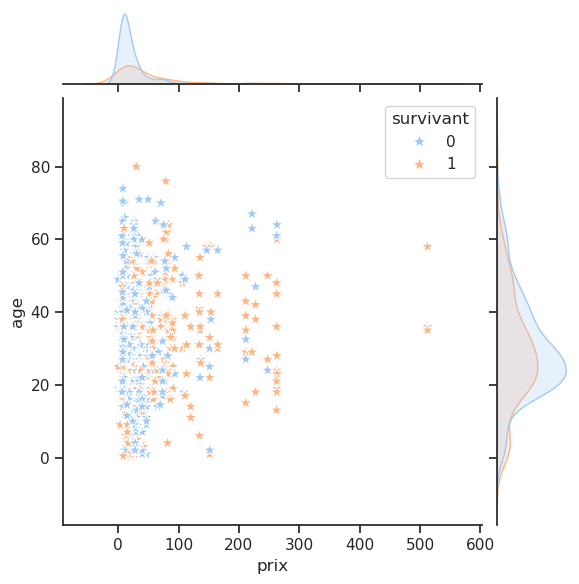

In [ ]:
# joint
sns.jointplot(data=df, x='prix', y='age', hue='survivant', marker="*", s=100);

In [471]:
px.scatter(df, x='prix', y='age', color='survivant', marginal_x='histogram', marginal_y='histogram')

### Lien entre 4 caractéristiques : le prix, l'âge, le sexe et les chances de survie

Nous souhaitons explorer la relation entre le prix payé et l'âge, tout en tenant compte du statut de survie (`survivant`) et du sexe.

La commande `lmplot()` est utilisée pour afficher une **régression linéaire** entre deux variables continues tout en permettant de visualiser la relation à l'aide de couleurs et de facettes.

- Le graphique affiche une régression linéaire entre les deux variables continues `prix` et `age`. Cela signifie qu'une droite (ou un autre modèle de régression si spécifié) est tracée pour chaque groupe de la variable `survivant`. La ligne de régression montre la tendance générale de la relation entre prix et âge. Par exemple, on observe que les personnes plus âgées ont tendance à payer plus cher.
- En fonction de la variable `hue='survivant'`, chaque groupe (survivant vs non-survivant) aura une couleur différente. Cela permet de comparer les relations entre prix et âge pour chaque groupe de manière visuellement distincte.
- Grâce à l'argument `col='sexe'`, on a des graphiques séparés pour chaque niveau de la variable sexe. Cela permet de visualiser comment la relation entre prix et âge varie entre les hommes et les femmes, par exemple.
- Le paramètre `markers=['o', 'x']` permet d'utiliser différents types de marqueurs pour les points représentant les survivants et les non-survivants, facilitant ainsi la distinction visuelle entre les deux groupes.

Ce graphique est pertinent si on pense que la relation entre deux variables continues est linéaire (ou presque linéaire) et souhaitons l'examiner graphiquement tout en incluant des groupes distincts (par exemple, selon `survivant`).

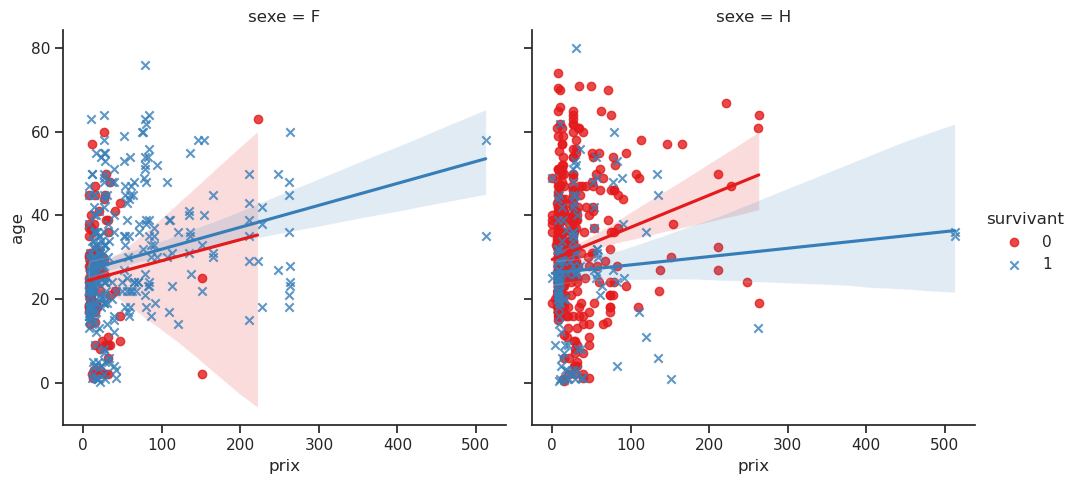

In [472]:
# On ajoute une quatrième dimension : le sexe
sns.lmplot(data=df, x='prix', y='age', hue='survivant', col='sexe', markers=['o', 'x'], palette='Set1');

Un graphique 3D avec la couleur comme 4e dimension est également possible :

In [473]:
# df['survivant'] = df['survivant'].astype('category')

df['survivant_code'] = df['survivant'].map({0: 'Non', 1: 'Oui'})

px.scatter_3d(
    df, 
    x='prix', 
    y='age', 
    z='sexe', 
    # color='survivant',
    color='survivant_code', 
    # Si la colonne est numérique, on peut la colorer mais il faut color_continuous_scale
    # color_continuous_scale='sunset',
    # On l'a transformée en catégorielle pour utiliser color_discrete_sequence
    color_discrete_sequence=['green', 'red'],  # il faut que 'survivant' soit une variable catégorielle !
    # labels={'prix': 'Prix', 'age': 'Âge', 'sexe': 'Sexe', 'survivant_code': 'Survivant'},
    # title='Classe vs Age vs Sexe selon le statut de survie',
)

## Aggregations

<div class="alert alert-info">

Dans cette partie nous allons utiliser les méthodes suivantes :

```python
.value_counts()
.corr()
.crosstab() 
```

</div>

### Masques et `value_counts`

Parmi les survivants, combien étaient des hommes et combien étaient des femmes ?

In [474]:
mask = (df['survivant'] == 1)
df[mask]['sexe'].value_counts()
# df[mask]['sexe'].value_counts().plot(kind='bar') ;

sexe
F    339
H    161
Name: count, dtype: int64

Parmi les enfants, les filles ont-elles été plus sauvées que les garçons ?  

In [475]:
mask_mineur_homme = (df['age'] < 10) & (df['sexe']=="H")
df[mask_mineur_homme]['survivant'].value_counts()

survivant
1    25
0    18
Name: count, dtype: int64

In [476]:
mask_mineur_femme = (df['age'] < 10) & (df['sexe']=="F")
df[mask_mineur_femme]['survivant'].value_counts()

survivant
1    25
0    14
Name: count, dtype: int64

### Corrélation entre les données : `corr`

La corrélation est le degré auquel deux ou plusieurs attributs ou mesures sur le même groupe d'éléments ont tendance à varier ensemble.

Les corrélations sont parmi les éléments les plus courants et les plus utiles de l'analyse des données. Qu'est-ce qui bouge avec quoi ? Quelles variables sont « dépendantes » et lesquelles sont « indépendantes » ? Quelles sont donc les questions pour lesquelles nous pourrions vouloir trouver des corrélations ?

Quelles sont les corrélations que nous pourrions rechercher ?

- Existe-t-il une corrélation entre l'âge et le prix du billet ?
- Existe-t-il une corrélation entre la classe et la survie ? Les riches ont-ils survécu davantage que les travailleurs ?
- Y a-t-il une corrélation entre l'âge et la survie ? 
- Les femmes et les enfants ont-ils vraiment le droit de passer en premier ?

Nous connaissons tous le vieil adage selon lequel, lorsqu'un navire coule, ce sont « les femmes et les enfants d'abord » qui montent à bord des canots de sauvetage. Ce vieil adage s'est-il vérifié sur le Titanic ? Les femmes et les enfants ont-ils été plus nombreux à survivre que les hommes ? Le sexe, l'âge ou la classe sociale des passagers du Titanic ont-ils joué un rôle déterminant dans leur survie ?

Si les femmes et les enfants ont survécu plus que les hommes, il devrait y avoir une corrélation positive entre la survie et le sexe et la survie et l'âge.

La méthode `.corr()` de pandas permet de trouver la corrélation entre deux caractéristiques quelconques d'un jeu de données.

In [477]:
df['age'].corr(df['survivant'])

-0.055512520192146246

Une valeur +1 signifie qu'il existe une corrélation positive parfaite entre deux caractéristiques, c'est-à-dire que lorsqu'une caractéristique augmente, l'autre augmente exactement dans les mêmes proportions.

Zéro signifie qu'il n'y a pas de corrélation entre deux caractéristiques. Elles se déplacent complètement au hasard l'une par rapport à l'autre.

Une valeur -1 signifie qu'il existe une corrélation parfaite, négative ou inverse entre deux caractéristiques. Lorsqu'une caractéristique augmente, l'autre diminue et vice versa.

D'après la corrélation entre le sexe et la survie (53 %) et l'âge et la survie (-0,05 %), nous pouvons affirmer certaines choses :

- le fait qu'un passager soit un homme était fortement corrélé négativement avec sa survie à bord du Titanic.
- le fait qu'un passager soit plus âgé est très faiblement corrélé négativement avec sa survie.

Mais « l'âge » n'est pas « les enfants », n'est-ce pas ? Comment savoir si le fait d'avoir moins de 10 ans augmentait les chances de survie ? Quelle était la probabilité qu'une personne de moins de 10 ans survive par rapport à une personne de plus de 10 ans ?

In [478]:
masque = df['age'] < 10
df[masque]['age'].corr(df['survivant'])

-0.14006219496281994

On ne peut pas calculer la corrélation avec le sexe car c'est une variable catégorielle. On peut utiliser la méthode `groupby()` pour regrouper les données par sexe et calculer la moyenne de survie pour chaque groupe. Ou sinon ajouter une colonne où les valeurs catégorielles sont encodées par des valeurs numériques, par exemple 0 pour les hommes et 1 pour les femmes.

In [479]:
# Catégorisation de la variable 'sexe' en 'sexe_code'
df['sexe_code'] = df['sexe'].astype('category').cat.codes
# df['sexe_code'] = df['sexe'].map({'H': 0, 'F': 1})
# df['sexe_code'] = df['sexe'].replace({'H': 0, 'F': 1})
df

,classe,survivant,sexe,age,prix,port_depart,age_group,personne,survivant_code,sexe_code
0,1,1,F,29.0000,211.3375,S,20-30,femme,Oui,0
1,1,1,H,0.9167,151.5500,S,0-10,enfant,Oui,1
2,1,0,F,2.0000,151.5500,S,0-10,enfant,Non,0
3,1,0,H,30.0000,151.5500,S,20-30,homme,Non,1
4,1,0,F,25.0000,151.5500,S,20-30,femme,Non,0
...,...,...,...,...,...,...,...,...,...,...
1304,3,0,F,14.5000,14.4542,C,10-20,femme,Non,0
1305,3,0,F,NaN,14.4542,C,Unknown,femme,Non,0
1306,3,0,H,26.5000,7.2250,C,20-30,homme,Non,1
1307,3,0,H,27.0000,7.2250,C,20-30,homme,Non,1


Pour l'instant, examinons la matrice de corrélation.

In [480]:
corr_matrix = df[['survivant', 'sexe_code', 'age', 'classe', 'prix']].corr()

# Ordonner les colonnes et les lignes selon la corrélation avec la variable 'survivant'
sorted_columns = corr_matrix['survivant'].abs().sort_values(ascending=False).index
sorted_corr_matrix = corr_matrix.loc[sorted_columns, sorted_columns]

corr_matrix['survivant']

survivant    1.000000
sexe_code   -0.528693
age         -0.055513
classe      -0.312469
prix         0.244265
Name: survivant, dtype: float64

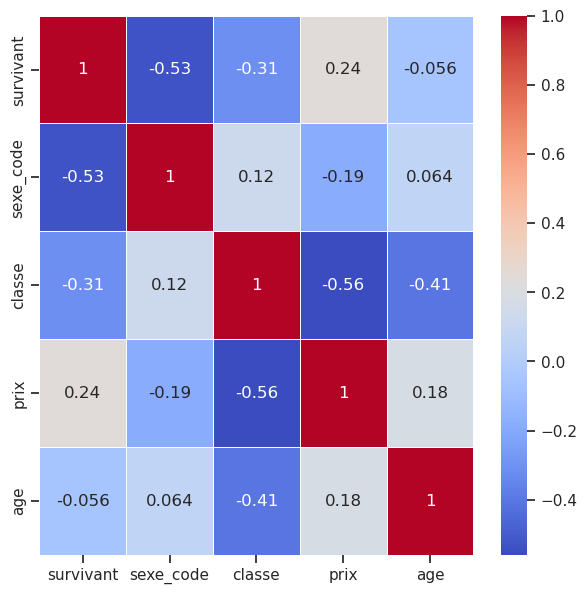

In [481]:
plt.figure(figsize=(7, 7))
sns.heatmap(sorted_corr_matrix, linewidths=0.5, annot=True, cbar=True, cmap="coolwarm");

In [482]:
px.imshow(sorted_corr_matrix, text_auto='.2f', color_continuous_scale='RdBu_r', aspect='auto')

In [483]:
# df['personne_code'] = df['personne'].astype('category').cat.codes
# corr_matrix = df[['survivant','personne_code','age','classe']].corr()
# sorted_columns = corr_matrix['survivant'].abs().sort_values(ascending=False).index
# sorted_corr_matrix = corr_matrix.loc[sorted_columns, sorted_columns]
# plt.figure(figsize=(10, 10))
# sns.heatmap(sorted_corr_matrix, linewidths=0.5, annot=True, cbar=True, cmap="coolwarm");


In [484]:
# dftemp = df[['survivant','sexe_code','age','classe']]
# corr_matrix = dftemp.corr()['survivant'].sort_values(ascending=False)

# # Sélection des colonnes ordonnées par corrélation avec 'survivant' (à l'exclusion de 'survivant' elle-même)
# sorted_columns = corr_matrix.index.tolist()[1:]

# # Création du heatmap avec Seaborn
# sns.heatmap(dftemp[sorted_columns].corr(), annot=True, linewidths=0.5, cmap="coolwarm", cbar=True);

### Analyse par groupes

#### `groupby()`

Taux de survie par sexe : les 3/4 des femmes ont survécu contre 1/5 des hommes, comme le montre le tableau suivant.

In [485]:
df.groupby('sexe')['survivant'].mean()

sexe
F    0.727468
H    0.190985
Name: survivant, dtype: float64

Taux de survie par âge : plus de la moitié des moins de 10 ans ont survécu.

In [486]:
# observed=False pour inclure les catégories sans valeurs
df.groupby('age_group', observed=False)['survivant'].mean()
# df.groupby('age_group', observed=False)['survivant'].mean().plot(kind='bar', edgecolor='black');

age_group
0-10       0.581395
10-20      0.395062
20-30      0.371191
30-40      0.423810
40-50      0.393939
50-60      0.483871
60-70      0.222222
70-80      0.333333
Unknown    0.277567
Name: survivant, dtype: float64

Étudions les relations entre sexe, classe et survie. Nous regroupons les données d'abord par sexe et classe, puis nous sélectionnons le taux de survie et enfin calculons le taux de survie moyen pour chaque groupe.

In [487]:
df.groupby(['sexe','classe'])['survivant'].agg('mean').unstack()

classe,1,2,3
sexe,,,
F,0.965278,0.886792,0.490741
H,0.340782,0.146199,0.152130


On note que la classe sociale a un impact sur la survie. Les femmes de première classe ont survécu à 96 %, contre 50 % pour celle de troisième classe. En ce qui concerne les hommes, 36 % des hommes de première classe ont survécu, contre 13 % pour ceux de troisième classe.

#### `pivot_table()`

Pour obtenir les mêmes résultats que précédemment, on peut utiliser la méthode `pivot_table()` qui permet de créer un tableau croisé dynamique. Voici un petit dessin pour comprendre :

Combien de survivants par classe et sexe ?

In [488]:
df.pivot_table(index='sexe', columns='classe', values='survivant', aggfunc='sum')

classe,1,2,3
sexe,,,
F,139,94,106
H,61,25,75


In [489]:
df.pivot_table(index='sexe', columns='classe', values='survivant', aggfunc='mean')

classe,1,2,3
sexe,,,
F,0.965278,0.886792,0.490741
H,0.340782,0.146199,0.152130


On peut spécifier plusieurs niveaux d'index pour obtenir des résultats plus détaillés, ici on a ajouté le groupe d'âge et, pour chaque groupe, le sexe.

In [490]:
df.pivot_table(index=['age_group','sexe'], columns='classe', values='survivant', aggfunc='sum', observed=False)

classe             1     2     3
age_group sexe                  
0-10      F      0.0  11.0  14.0
          H      3.0  11.0  11.0
10-20     F     15.0  15.0  20.0
          H      3.0   2.0   9.0
20-30     F     32.0  34.0  25.0
          H     12.0   5.0  26.0
30-40     F     33.0  19.0   9.0
          H     14.0   3.0  11.0
40-50     F     22.0  11.0   3.0
          H     13.0   1.0   2.0
50-60     F     21.0   2.0   NaN
          H      7.0   0.0   0.0
60-70     F      4.0   NaN   1.0
          H      0.0   1.0   0.0
70-80     F      1.0   NaN   NaN
          H      1.0   NaN   0.0
Unknown   F     11.0   2.0  34.0
          H      8.0   2.0  16.0

La même technique peut s'appliquer pour les colonnes :

In [491]:
df.pivot_table(index=['age_group','sexe'], columns=['classe','port_depart'], values='survivant', aggfunc='sum', observed=False)

classe             1               2               3            
port_depart        C    Q     S    C    Q     S    C     Q     S
age_group sexe                                                  
0-10      F      NaN  NaN   0.0  2.0  NaN   9.0  6.0   NaN   8.0
          H      1.0  NaN   2.0  1.0  NaN  10.0  2.0   0.0   9.0
10-20     F      5.0  NaN  10.0  2.0  NaN  13.0  7.0   4.0   9.0
          H      2.0  NaN   1.0  1.0  NaN   1.0  3.0   0.0   6.0
20-30     F     16.0  NaN  16.0  7.0  1.0  26.0  2.0   4.0  19.0
          H      7.0  NaN   5.0  2.0  NaN   3.0  5.0   2.0  19.0
30-40     F     15.0  2.0  15.0  NaN  NaN  19.0  1.0   0.0   8.0
          H      6.0  NaN   8.0  0.0  0.0   3.0  1.0   0.0  10.0
40-50     F     15.0  NaN   7.0  NaN  NaN  11.0  1.0   NaN   2.0
          H      6.0  0.0   7.0  0.0  NaN   1.0  0.0   0.0   2.0
50-60     F     11.0  NaN  10.0  NaN  NaN   2.0  NaN   NaN   NaN
          H      4.0  NaN   3.0  NaN  0.0   0.0  NaN   NaN   0.0
60-70     F      1.0  NaN   2.0  NaN  NaN   NaN  NaN   NaN   1.0
          H      0.0  NaN   0.0  NaN  0.0   1.0  NaN   0.0   0.0
70-80     F      NaN  NaN   1.0  NaN  NaN   NaN  NaN   NaN   NaN
          H      0.0  NaN   1.0  NaN  NaN   NaN  NaN   0.0   0.0
Unknown   F      6.0  NaN   5.0  NaN  1.0   1.0  5.0  25.0   4.0
          H      2.0  NaN   6.0  1.0  0.0   1.0  4.0   5.0   7.0

Pourcentage de survivants par sexe et age :

In [492]:
df.pivot_table(index='sexe', columns='age_group', values='survivant', aggfunc='sum', observed=False) 
# Comme la colonne 'survivant' vaut 0 si décédé et 1 si survivant, la somme donne le nombre de survivants

age_group,0-10,10-20,20-30,30-40,40-50,50-60,60-70,70-80,Unknown
sexe,,,,,,,,,
F,25,50,91,61,36,23,5,1,47
H,25,14,43,28,16,7,1,1,26


### Tableaux croisés `crosstab()`

Un tableau croisé `crosstab()` est un cas particulier de tableau croisé dynamique `pivot_table()` qui calcule la fréquence des groupes.

D'après l'histoire, la plupart de ceux qui ont survécu étaient des femmes. Vérifions si c'est bien le cas en calculant le nombre de survivants par sexe dans un tableau croisé.

In [493]:
sex_survivant = pd.crosstab(df['sexe'], 
                             df['survivant'],
                             # normalize='index'
                             # normalize='columns'
                             # normalize='all'
                             )
sex_survivant

survivant,0,1
sexe,,
F,127,339
H,682,161


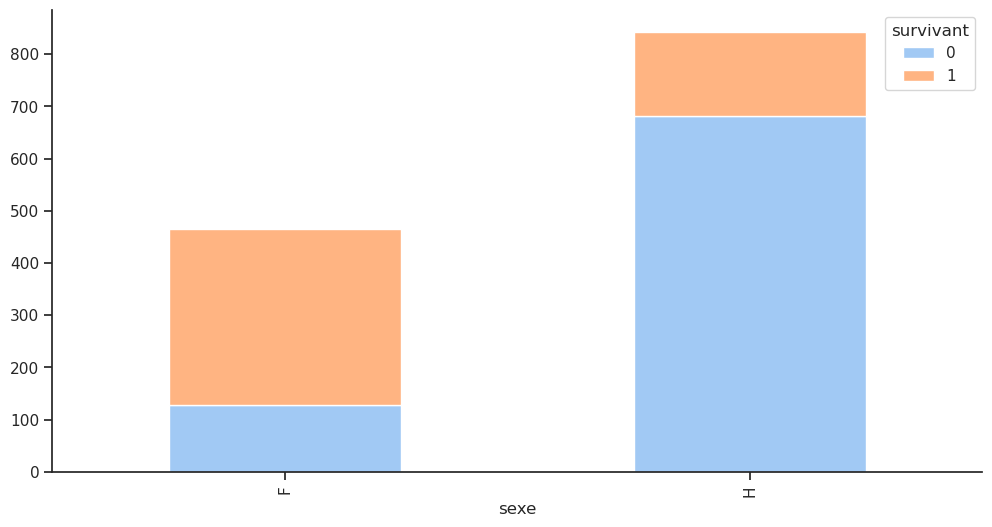

In [494]:
sex_survivant.plot(kind='bar', stacked=True);

In [496]:
px.bar(sex_survivant, barmode='stack', text_auto=True)

## Autres ressources

Voici trois excellentes vidéos (en français) de la chaîne YouTube **Machine Learnia** qui expliquent comment faire une analyse statistique du jeu de données du Titanic :

1. [Vidéo 1 : Analyse exploratoire de données](https://www.youtube.com/watch?v=zZkNOdBWgFQ)

<iframe width="560" height="315" src="https://www.youtube.com/embed/zZkNOdBWgFQ" frameborder="0" allowfullscreen></iframe>

2. [Vidéo 2 : Data visualization (à partir de 19:50)](https://www.youtube.com/watch?v=qHRLG5hsW9I&list=PLO_fdPEVlfKqMDNmCFzQISI2H_nJcEDJq&index=18)

<iframe width="560" height="315" src="https://www.youtube.com/embed/qHRLG5hsW9I?start=1190" frameborder="0" allowfullscreen></iframe>

3. [Vidéo 3 : Feature engineering (à partir de 6:35)](https://www.youtube.com/watch?v=xYgfIRzNPlo&list=PLO_fdPEVlfKqMDNmCFzQISI2H_nJcEDJq&index=19)

<iframe width="560" height="315" src="https://www.youtube.com/embed/xYgfIRzNPlo?start=395" frameborder="0" allowfullscreen></iframe>